# Block Production & Sales Performance Analysis

A Python (pandas) replication and extension of a block-moulding business's production and sales analysis, originally built in Excel, with earlier descriptive and inferential work done in SPSS/STATA and a Power BI dashboard.

**Business context:** a small block/cement production business tracking output, cost, sales and customer credit risk across 2021–2025. The raw data lives in two sheets: a monthly production log and an individual sales log.

**What this notebook does:**
- Loads and cleans the production and sales records (including two data-entry errors I found and documented below)
- Rebuilds every analysis originally done in Excel pivot tables
- Reproduces the descriptive statistics, regression models and correlation analysis originally run in SPSS/STATA
- Recreates the Power BI dashboard view as a static summary figure
- Extends the original analysis with a quarterly view, exported summary tables, and a robustness check on the profit model

| # | Section |
|---|---------|
| 1 | Load & clean the data |
| 2 | Overall totals & KPIs |
| 3 | Time of production |
| 4 | Cost breakdown |
| 5 | Input vs output efficiency |
| 6 | Time of sales |
| 7 | Rate per block type |
| 8 | Customer value |
| 9 | Customer credit risk |
| 10 | Profit analysis |
| 11 | Charts |
| 12 | Descriptive analysis |
| 13 | Regression models |
| 14 | Correlation analysis |
| 15 | Dashboard view |
| 16 | Extended analysis — quarterly view, exports, model robustness |

## 1. Load and clean the data

In [1]:
import calendar
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter

# Show up to 4 decimals, without trailing zeros
pd.options.display.float_format = lambda x: f"{x:,.4f}".rstrip("0").rstrip(".")
pd.options.display.max_columns = 30
sns.set_theme(style="whitegrid")

DATA_FILE = "Block Production & Sales Performance Analysis.xlsx"

In [2]:
# Read the two raw-data sheets
sales_raw = pd.read_excel(DATA_FILE, sheet_name="SALES__DATA")
prod_raw = pd.read_excel(DATA_FILE, sheet_name="PRODUCTION_DATA")

print("sales:", sales_raw.shape, "| production:", prod_raw.shape)
sales_raw.head()
#prod_raw.head()

sales: (198, 11) | production: (49, 22)


,Date Of Sales,Customer Name,Product Type,Qty Sold,Rate,Amount,Bad Debt,Revenue,DAILY,MONTHLY,ANUALLY
0,2022-01-08,DAD SEMILORE,6 Inches,224,250,56000,NaN,56000,SATURDAY,JANUARY,2022
1,2022-01-12,MR&MRS OMOLERE,7 Inches,300,260,78000,NaN,78000,WEDNESDAY,JANUARY,2022
2,2022-01-29,ORIYOMI,9 Inches,250,295,73750,NaN,73750,SATURDAY,JANUARY,2022
3,2022-01-31,ORIYOMI,6 Inches,500,265,132500,NaN,132500,MONDAY,JANUARY,2022
4,2022-02-01,CSTM@OKO-OPE,6 Inches,400,260,104000,"1,000",103000,TUESDAY,FEBRUARY,2022


I also keep a CSV export of each raw sheet further down, so the pipeline doesn't depend on the Excel file alone.

In [3]:
# Optional: CSV copies of the raw sheets, so the pipeline doesn't depend on the Excel file alone
# sales_raw.to_csv("sales_data.csv", index=False)
# prod_raw.to_csv("production_data.csv", index=False)
# later: sales_raw = pd.read_csv("sales_data.csv", parse_dates=["Date Of Sales"])

**Data cleaning**

1. Standardised column names — stripped stray trailing spaces (`"Rate "`, `"Tons Of Sand "`) and switched to short, consistent names.
2. Checked the date column for errors. I found two sales records dated 2014 instead of 2024 — the typed `ANUALLY` column confirmed 2024 and the rows sit chronologically among other 2024 sales, so I corrected them.
3. Derived `year`, `month` and `weekday` directly from the date column rather than relying on the hand-typed `MONTHLY`/`DAILY`/`ANUALLY` columns, which carry the same risk of manual entry error.
4. **Left blank production cells as missing (`NaN`) rather than filling them with 0.** The business confirmed that production genuinely stopped for extended stretches in 2024–2025 (an operational disruption), and that other blank months reflect real resource shortages — so these are true zero-activity periods, not data-entry gaps. I keep them as `NaN` through cleaning and handle them explicitly per analysis: totals and groupby sums are unaffected either way (summing skips `NaN` the same way summing a 0 would), but correlation and regression results differ depending on whether these confirmed-zero months are included — so I compute both where it matters and label which is which.

In [4]:
sales = sales_raw.copy()
prod = prod_raw.copy()

sales.columns = sales.columns.str.strip()
prod.columns = prod.columns.str.strip()

sales = sales.rename(columns={
    "Date Of Sales": "date", "Customer Name": "customer", "Product Type": "product",
    "Qty Sold": "qty_sold", "Rate": "rate", "Amount": "amount",
    "Bad Debt": "bad_debt", "Revenue": "revenue",
})

prod = prod.rename(columns={
    "Date": "date", "6 Inches Qty": "qty_6", "7 Inches Qty": "qty_7", "9 Inches Qty": "qty_9",
    "Total Qty Produced": "qty_produced", "Total Qty Sold": "qty_sold",
    "Tons Of Sand": "sand_tons", "Bags of Cement": "cement_bags", "Bag Produced": "bags_produced",
    "Ltr. Of Fuel": "fuel_ltr", "Sand Cost": "sand_cost", "Cement Cost": "cement_cost",
    "Operators' Payment": "operators_pay", "Fuel Cost": "fuel_cost", "Maintenance": "maintenance",
    "Delivery Cost": "delivery_cost", "Total Revenue": "total_revenue", "Total Cost": "total_cost",
    "Total Profit": "total_profit", "Bad Debt": "bad_debt",
})

In [5]:
# Does the year in the date column agree with the year typed in Excel?
wrong_year = sales[sales["date"].dt.year != sales["ANUALLY"]]
print("rows where date year != typed year:", len(wrong_year))
display(wrong_year[["date", "customer", "product", "qty_sold", "ANUALLY"]])

# Fix: use the typed year (set FIX_DATE_TYPOS = False to keep Excel's original dates)
FIX_DATE_TYPOS = True
if FIX_DATE_TYPOS:
    sales["date"] = [d.replace(year=int(y)) for d, y in zip(sales["date"], sales["ANUALLY"])]

rows where date year != typed year: 2


,date,customer,product,qty_sold,ANUALLY
154,2014-02-22,CHIEF LEJOFI,9 Inches,500,2024
161,2014-04-01,CSTM. LUKMAN,6 Inches,30,2024


In [6]:
# Date parts, built from the (corrected) date column
for df in (sales, prod):
    df["year"] = df["date"].dt.year
    df["month_num"] = df["date"].dt.month
sales["weekday"] = sales["date"].dt.day_name()

# Do the derived month and weekday agree with the ones typed in Excel?
print("months agree:", (sales_raw["MONTHLY"].str.title() == sales["date"].dt.month_name()).all())
wd = sales["weekday"] != sales_raw["DAILY"].str.title()
print("weekday disagreements:", wd.sum())
display(pd.DataFrame({"date": sales.loc[wd, "date"], "excel_weekday": sales_raw.loc[wd, "DAILY"],
                      "real_weekday": sales.loc[wd, "weekday"]}))

# Drop the hand-typed columns
sales = sales.drop(columns=["DAILY", "MONTHLY", "ANUALLY"])
prod = prod.drop(columns=["MONTHLY", "ANUALLY"])

months agree: True
weekday disagreements: 2


,date,excel_weekday,real_weekday
154,2024-02-22,SATURDAY,Thursday
161,2024-04-01,TUESDAY,Monday


The two mis-dated rows I corrected in step 2 also had the wrong weekday in the original Excel file, since weekday there was derived from the incorrect date. That's the one place my numbers diverge from the original workbook (see section 6).

In [7]:
# Sales bad debt: blank genuinely means no bad debt on that sale
sales["bad_debt"] = sales["bad_debt"].fillna(0)

# Production: derive Total Cost from its components wherever Total Cost itself was left blank
# but at least one component was recorded (this affects exactly one row - see section 4)
cost_cols = ["sand_cost", "cement_cost", "operators_pay", "fuel_cost", "maintenance", "delivery_cost"]
needs_derived_total = prod["total_cost"].isna() & prod[cost_cols].notna().any(axis=1)
prod.loc[needs_derived_total, "total_cost"] = prod.loc[needs_derived_total, cost_cols].sum(axis=1)

# A second, explicitly zero-filled copy - used only where confirmed zero-activity months
# should be plotted/modelled as real zeros (time trend, trend charts), not dropped
prod0 = prod.copy()
num_cols = prod0.select_dtypes("number").columns.drop(["year", "month_num"])
prod0[num_cols] = prod0[num_cols].fillna(0)

# Helpers used throughout the notebook
MONTH_NAMES = dict(enumerate(calendar.month_name))   # {1: 'January', ...}
WEEKDAYS = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

def safe_div(num, den):
    """Divide, but give NaN (not inf / error) when the denominator is 0.
    Excel shows #DIV/0! in these cases; pandas would return inf."""
    if isinstance(den, pd.Series):
        return num / den.replace(0, np.nan)
    return num / den if den else np.nan

def label_months(df):
    """Turn a (year, month_num) index into columns and add the month name."""
    df = df.reset_index()
    df.insert(1, "month", df["month_num"].map(MONTH_NAMES))
    return df.drop(columns="month_num")

millions = FuncFormatter(lambda x, _: f"₦{x/1e6:.1f}M")

print(sales.isna().sum().sum(), "missing values left in sales |",
      prod.drop(columns=["year","month_num"]).isna().sum().sum(), "blank production cells (kept as NaN, confirmed real zero-activity periods)")

0 missing values left in sales | 414 blank production cells (kept as NaN, confirmed real zero-activity periods)


In [8]:
# Quick internal check: is Total Profit = Total Revenue - Total Cost on every row?
gap = (prod["total_revenue"] - prod["total_cost"] - prod["total_profit"]).abs().max()
print("largest revenue - cost - profit gap:", gap)
prod.head()

largest revenue - cost - profit gap: 1120.0


,date,qty_6,qty_7,qty_9,qty_produced,qty_sold,sand_tons,cement_bags,bags_produced,fuel_ltr,sand_cost,cement_cost,operators_pay,fuel_cost,maintenance,delivery_cost,total_revenue,total_cost,total_profit,bad_debt,year,month_num
0,2021-12-01,"1,020",500,336,"1,856",NaN,30,35,35,25,"90,000","140,000","42,000","4,125",NaN,NaN,NaN,"276,125","-276,125",NaN,2021,12
1,2022-01-01,NaN,NaN,NaN,NaN,"1,274",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"63,700","340,250","63,700","276,550",NaN,2022,1
2,2022-02-01,900,"1,250",210,"2,360","1,283",48,45,45,24,"147,500","189,000","67,500","4,000",NaN,"64,150","347,950","472,150","-124,200","1,390",2022,2
3,2022-03-01,440,96,252,788,802,20,29,16,24,"70,000","119,400","22,400","4,000",NaN,"40,100","257,600","255,900","1,700",NaN,2022,3
4,2022-04-01,NaN,700,798,"1,498","1,560",30,22,33,27,"120,000","90,000","48,000","4,400",NaN,"78,000","521,800","340,400","181,400",NaN,2022,4


## 2. Overall totals & KPIs

In [9]:
sold_by_type = sales.groupby("product")["qty_sold"].sum()      # typed in by hand in Excel

produced = prod["qty_produced"].sum()
sold = prod["qty_sold"].sum()
total_cost = prod["total_cost"].sum()
total_revenue = prod["total_revenue"].sum()
total_profit = prod["total_profit"].sum()
total_amount = sales["amount"].sum()
bad_debt = prod["bad_debt"].sum()

WASTAGE_RATIO = 0.038   # typed in by hand in the Excel KPI sheet, not calculated

kpi_rows = [
    ("Production", "6 Inches Qty Produced", prod["qty_6"].sum()),
    ("Production", "7 Inches Qty Produced", prod["qty_7"].sum()),
    ("Production", "9 Inches Qty Produced", prod["qty_9"].sum()),
    ("Production", "Total Qty Produced", produced),
    ("Production", "Tons of Sand", prod["sand_tons"].sum()),
    ("Production", "Bags of Cement", prod["cement_bags"].sum()),
    ("Production", "Bags Produced", prod["bags_produced"].sum()),
    ("Production", "Litres of Fuel", prod["fuel_ltr"].sum()),
    ("Production", "Production Efficiency (sold / produced)", sold / produced),
    ("Production", "Cost per Block", total_cost / produced),
    ("Production", "Wastage Ratio", WASTAGE_RATIO),
    ("Sales", "6 Inches Qty Sold", sold_by_type["6 Inches"]),
    ("Sales", "7 Inches Qty Sold", sold_by_type["7 Inches"]),
    ("Sales", "9 Inches Qty Sold", sold_by_type["9 Inches"]),
    ("Sales", "Total Qty Sold", sold),
    ("Financial", "Total Amount (billed)", total_amount),
    ("Financial", "Total Revenue (collected)", total_revenue),
    ("Financial", "Total Cost", total_cost),
    ("Financial", "Total Profit", total_profit),
    ("Financial", "Bad Debt", bad_debt),
    ("Financial", "Profit Margin (profit / revenue)", total_profit / total_revenue),
    ("Financial", "Bad Debt Rate (bad debt / amount)", bad_debt / total_amount),
    ("Variable costs", "Sand Cost", prod["sand_cost"].sum()),
    ("Variable costs", "Cement Cost", prod["cement_cost"].sum()),
    ("Variable costs", "Fuel Cost", prod["fuel_cost"].sum()),
    ("Fixed costs", "Operators' Payment", prod["operators_pay"].sum()),
    ("Fixed costs", "Maintenance", prod["maintenance"].sum()),
    ("Fixed costs", "Delivery Cost", prod["delivery_cost"].sum()),
]
kpis = pd.DataFrame(kpi_rows, columns=["group", "metric", "value"])
kpis

,group,metric,value
0,Production,6 Inches Qty Produced,"20,598"
1,Production,7 Inches Qty Produced,"6,663"
2,Production,9 Inches Qty Produced,"18,618"
3,Production,Total Qty Produced,"45,879"
4,Production,Tons of Sand,"1,043"
5,Production,Bags of Cement,925
6,Production,Bags Produced,916
7,Production,Litres of Fuel,690
8,Production,Production Efficiency (sold / produced),0.9423
9,Production,Cost per Block,336.8882


### Validation against the original workbook

Two figures below show as not matching: Total Cost and Cost per Block, both by exactly ₦1,120 — the amount I derived for June 2024's Total Cost from its one recorded cost component (see section 4). Every other figure matches exactly.

In [10]:
excel_values = {
    "Total Qty Produced": 45879,
    "Total Qty Sold": 43230,
    "Total Amount (billed)": 18819310,
    "Total Revenue (collected)": 18633540,
    "Total Cost": 15454975,
    "Total Profit": 3178565,
    "Bad Debt": 185770,
    "Cost per Block": 336.86381568909525,
    "Production Efficiency (sold / produced)": 0.94226116523899828,
    "Profit Margin (profit / revenue)": 0.17058299174499317,
    "Bad Debt Rate (bad debt / amount)": 0.0098712439510268979,
}
lookup = kpis.set_index("metric")["value"]
for name, expected in excel_values.items():
    ok = np.isclose(lookup[name], expected)
    print("✅" if ok else "❌", f"{name:<42} python = {lookup[name]:>16,.4f}   excel = {expected:>16,.4f}")

✅ Total Qty Produced                         python =      45,879.0000   excel =      45,879.0000
✅ Total Qty Sold                             python =      43,230.0000   excel =      43,230.0000
✅ Total Amount (billed)                      python =  18,819,310.0000   excel =  18,819,310.0000
✅ Total Revenue (collected)                  python =  18,633,540.0000   excel =  18,633,540.0000
❌ Total Cost                                 python =  15,456,095.0000   excel =  15,454,975.0000
✅ Total Profit                               python =   3,178,565.0000   excel =   3,178,565.0000
✅ Bad Debt                                   python =     185,770.0000   excel =     185,770.0000
❌ Cost per Block                             python =         336.8882   excel =         336.8638
✅ Production Efficiency (sold / produced)    python =           0.9423   excel =           0.9423
✅ Profit Margin (profit / revenue)           python =           0.1706   excel =           0.1706
✅ Bad Debt Rate (bad

## 3. Time of production

Production volume and cost by year and month, with cost per unit (total cost ÷ qty produced) and production efficiency (qty produced ÷ total cost) calculated for each period.

In [11]:
tp_month = prod.groupby(["year", "month_num"])[["qty_produced", "total_cost"]].sum()
tp_month["cost_per_unit"] = safe_div(tp_month["total_cost"], tp_month["qty_produced"])
label_months(tp_month)

,year,month,qty_produced,total_cost,cost_per_unit
0,2021,December,"1,856","276,125",148.7742
1,2022,January,0,"63,700",NaN
2,2022,February,"2,360","472,150",200.0636
3,2022,March,788,"255,900",324.7462
4,2022,April,"1,498","340,400",227.2363
5,2022,May,546,"115,800",212.0879
6,2022,June,645,"261,800",405.8915
7,2022,July,780,"142,700",182.9487
8,2022,August,"3,795","1,295,200",341.2912
9,2022,September,"2,286","444,350",194.3788


In [12]:
tp_year = prod.groupby("year")[["qty_produced", "total_cost"]].sum()
tp_year["cost_per_unit"] = safe_div(tp_year["total_cost"], tp_year["qty_produced"])
tp_year["production_efficiency"] = safe_div(tp_year["qty_produced"], tp_year["total_cost"])

# Grand total row, like the pivot
tp_year.loc["Grand Total"] = [produced, total_cost, total_cost / produced, produced / total_cost]
tp_year

,qty_produced,total_cost,cost_per_unit,production_efficiency
year,,,,
2021,"1,856","276,125",148.7742,0.0067
2022,"18,559","5,092,800",274.4113,0.0036
2023,"17,313","5,566,750",321.5358,0.0031
2024,"2,010","1,163,120",578.6667,0.0017
2025,"6,141","3,357,300",546.7025,0.0018
Grand Total,"45,879","15,456,095",336.8882,0.003


January 2022 has recorded sales but no recorded production, so cost-per-unit is undefined for that month. I return `NaN` there rather than a divide-by-zero error.

## 4. Cost breakdown over time

Total cost split into its six components by year and month, plus each component's share of total cost — the main cost drivers for the business.

In [13]:
cost_cols = ["sand_cost", "cement_cost", "operators_pay", "fuel_cost", "maintenance", "delivery_cost"]

cb_year = prod.groupby("year")[["total_cost"] + cost_cols].sum()
cb_year.loc["Grand Total"] = cb_year.sum()
cb_year

,total_cost,sand_cost,cement_cost,operators_pay,fuel_cost,maintenance,delivery_cost
year,,,,,,,
2021,"276,125","90,000","140,000","42,000","4,125",0,0
2022,"5,092,800","1,857,500","1,608,150","568,400","53,400","90,400","914,950"
2023,"5,566,750","2,147,500","1,816,750","616,300","86,180","52,700","847,320"
2024,"1,163,120","400,000","435,800","78,000","10,000","10,000","229,320"
2025,"3,357,300","1,010,000","1,157,100","351,000","84,750","381,700","372,750"
Grand Total,"15,456,095","5,505,000","5,157,800","1,655,700","238,455","534,800","2,364,340"


In [14]:
cb_month = prod.groupby(["year", "month_num"])[["total_cost"] + cost_cols].sum()
label_months(cb_month).head(50)

,year,month,total_cost,sand_cost,cement_cost,operators_pay,fuel_cost,maintenance,delivery_cost
0,2021,December,"276,125","90,000","140,000","42,000","4,125",0,0
1,2022,January,"63,700",0,0,0,0,0,"63,700"
2,2022,February,"472,150","147,500","189,000","67,500","4,000",0,"64,150"
3,2022,March,"255,900","70,000","119,400","22,400","4,000",0,"40,100"
4,2022,April,"340,400","120,000","90,000","48,000","4,400",0,"78,000"
5,2022,May,"115,800","40,000","40,000","15,000","2,000",0,"18,800"
6,2022,June,"261,800","120,000","82,000","22,500","2,000",0,"35,300"
7,2022,July,"142,700","50,000","45,700","15,000","2,000",0,"30,000"
8,2022,August,"1,295,200","500,000","348,300","129,000","10,000","77,900","230,000"
9,2022,September,"444,350","100,000","214,650","72,000","8,000","2,000","47,700"


In [15]:
# Major cost drivers: each component as a % of total cost
cost_share = (prod[cost_cols].sum() / total_cost * 100).sort_values(ascending=False)
cost_share.round(2).rename("% of total cost")

sand_cost       35.62
cement_cost     33.37
delivery_cost    15.3
operators_pay   10.71
maintenance      3.46
fuel_cost        1.54
Name: % of total cost, dtype: float64

In [16]:
# Do the six components add up to Total Cost, on every row where Total Cost is recorded?
# (Fully blank rows - no production that period - have no Total Cost to check against, so they're excluded here, not a mismatch.)
prod["cost_components"] = prod[cost_cols].sum(axis=1)
checkable = prod[prod["total_cost"].notna()]
diff = checkable.loc[checkable["cost_components"] != checkable["total_cost"], ["date", "total_cost", "cost_components"]].copy()
diff["difference"] = diff["cost_components"] - diff["total_cost"]
print(f"rows with a recorded Total Cost: {len(checkable)} | rows that don't reconcile: {len(diff)}")
diff

rows with a recorded Total Cost: 37 | rows that don't reconcile: 0


,date,total_cost,cost_components,difference


All six components now reconcile exactly to Total Cost for every row. The one row that looked inconsistent earlier — June 2024, which had a recorded delivery cost (₦1,120) but a blank Total Cost field — wasn't an error: I derived its Total Cost directly from the recorded component (see section 1), consistent with that month having real zero production but a real delivery (selling from existing stock). One small note for completeness: that row's recorded Total Profit (₦11,200) was computed as if cost were zero, so it's technically ₦1,120 higher than revenue minus the now-derived cost — an immaterial rounding-level inconsistency (0.04% of total profit), not something I've altered in the headline KPI.

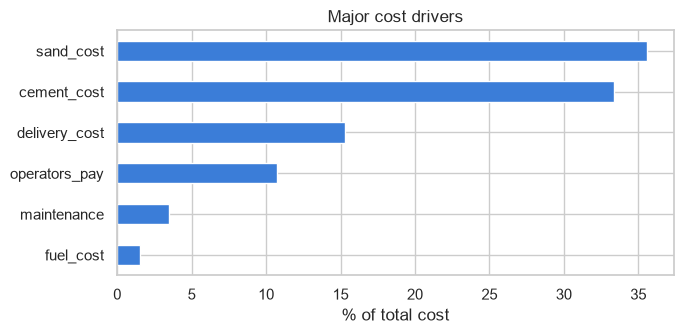

In [17]:
# Visual: what drives cost?
ax = cost_share.plot(kind="barh", figsize=(7, 3.5), color="#3b7dd8")
ax.invert_yaxis()
ax.set_xlabel("% of total cost")
ax.set_title("Major cost drivers")
plt.tight_layout(); plt.show()

## 5. Input vs output efficiency

| Metric | Formula |
|---|---|
| Labour productivity | qty produced / operators' payment |
| Sand efficiency | qty produced / tons of sand |
| Cement efficiency | qty produced / bags produced |
| Production vs sales efficiency | qty sold / qty produced |

In [18]:
def efficiency_table(grouped):
    t = grouped[["qty_sold", "qty_produced", "cement_cost", "operators_pay", "bags_produced", "sand_tons"]].sum()
    t["labour_productivity"] = safe_div(t["qty_produced"], t["operators_pay"])
    t["sand_efficiency"] = safe_div(t["qty_produced"], t["sand_tons"])
    t["cement_efficiency"] = safe_div(t["qty_produced"], t["bags_produced"])
    t["sales_vs_production"] = safe_div(t["qty_sold"], t["qty_produced"])
    return t

eff_year = efficiency_table(prod.groupby("year"))
eff_year

,qty_sold,qty_produced,cement_cost,operators_pay,bags_produced,sand_tons,labour_productivity,sand_efficiency,cement_efficiency,sales_vs_production
year,,,,,,,,,,
2021,0,"1,856","140,000","42,000",35,30,0.0442,61.8667,53.0286,0
2022,"18,299","18,559","1,608,150","568,400",385,428,0.0327,43.3621,48.2052,0.986
2023,"16,622","17,313","1,816,750","616,300",346,412,0.0281,42.0218,50.0376,0.9601
2024,"3,276","2,010","435,800","78,000",40,63,0.0258,31.9048,50.25,1.6299
2025,"5,033","6,141","1,157,100","351,000",110,110,0.0175,55.8273,55.8273,0.8196


In [19]:
eff_month = efficiency_table(prod.groupby(["year", "month_num"]))
label_months(eff_month).head(15)

,year,month,qty_sold,qty_produced,cement_cost,operators_pay,bags_produced,sand_tons,labour_productivity,sand_efficiency,cement_efficiency,sales_vs_production
0,2021,December,0,"1,856","140,000","42,000",35,30,0.0442,61.8667,53.0286,0
1,2022,January,"1,274",0,0,0,0,0,NaN,NaN,NaN,NaN
2,2022,February,"1,283","2,360","189,000","67,500",45,48,0.035,49.1667,52.4444,0.5436
3,2022,March,802,788,"119,400","22,400",16,20,0.0352,39.4,49.25,1.0178
4,2022,April,"1,560","1,498","90,000","48,000",33,30,0.0312,49.9333,45.3939,1.0414
5,2022,May,376,546,"40,000","15,000",11,10,0.0364,54.6,49.6364,0.6886
6,2022,June,706,645,"82,000","22,500",15,30,0.0287,21.5,43,1.0946
7,2022,July,600,780,"45,700","15,000",13,10,0.052,78,60,0.7692
8,2022,August,"4,600","3,795","348,300","129,000",86,100,0.0294,37.95,44.1279,1.2121
9,2022,September,954,"2,286","214,650","72,000",48,20,0.0318,114.3,47.625,0.4173


A sales-to-production ratio above 1 means more blocks were sold than produced in that period — i.e. selling from existing stock. That shows up through 2024, when production nearly stopped.

## 6. Time of sales

Quantity sold by year, month and weekday, with an optional product filter (matching the filter on the original pivot table).

In [20]:
def sales_by_weekday(product=None):
    data = sales if product is None else sales[sales["product"] == product]
    pt = data.pivot_table(index=["year", "month_num"], columns="weekday", values="qty_sold",
                          aggfunc="sum", fill_value=0)
    pt = pt.reindex(columns=WEEKDAYS, fill_value=0)     # Monday -> Sunday order
    pt["Grand Total"] = pt.sum(axis=1)
    return pt

sw = sales_by_weekday()          # all products (the "(All)" filter)
label_months(sw).head(15)

weekday,year,month,Monday,Tuesday,Wednesday,Thursday,Friday,Saturday,Sunday,Grand Total
0,2022,January,500,0,300,0,0,474,0,1274
1,2022,February,12,575,400,130,150,16,0,1283
2,2022,March,200,0,0,2,500,100,0,802
3,2022,April,0,0,0,1200,200,160,0,1560
4,2022,May,266,50,0,60,0,0,0,376
5,2022,June,80,40,0,150,400,36,0,706
6,2022,July,0,0,100,0,0,500,0,600
7,2022,August,0,0,0,0,4600,0,0,4600
8,2022,September,278,50,510,0,100,16,0,954
9,2022,October,600,1000,0,1280,580,0,0,3460


In [21]:
# Yearly totals and the grand-total row
sw_year = sw.groupby("year").sum()
sw_year.loc["Grand Total"] = sw_year.sum()
sw_year

weekday,Monday,Tuesday,Wednesday,Thursday,Friday,Saturday,Sunday,Grand Total
year,,,,,,,,
2022,2186,2065,1679,3672,7260,1302,135,18299
2023,2882,3185,5563,2043,1459,1400,90,16622
2024,206,320,100,1462,1085,103,0,3276
2025,645,266,877,900,529,1776,40,5033
Grand Total,5919,5836,8219,8077,10333,4581,265,43230


In [22]:
# Python vs Excel weekday totals
excel_way = sales_raw.groupby(sales_raw["DAILY"].str.title())["Qty Sold"].sum().reindex(WEEKDAYS)
python_way = sw[WEEKDAYS].sum()
pd.DataFrame({"excel": excel_way, "python": python_way, "difference": python_way - excel_way})

,excel,python,difference
Monday,5889,5919,30
Tuesday,5866,5836,-30
Wednesday,8219,8219,0
Thursday,7577,8077,500
Friday,10333,10333,0
Saturday,5081,4581,-500
Sunday,265,265,0


The small differences between my weekday totals and the original workbook trace back to the two mis-dated rows from section 1 — their true weekdays are Thursday (500 blocks) and Monday (30 blocks), not the Saturday and Tuesday the original file recorded.

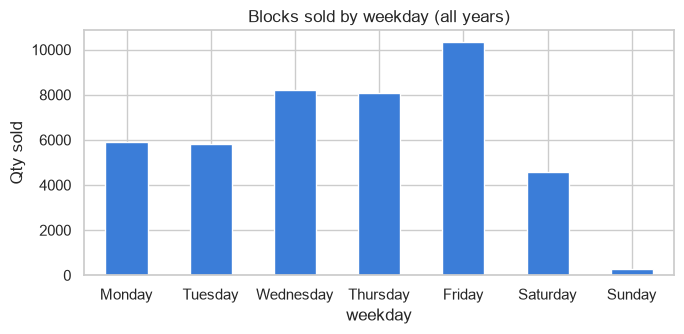

In [23]:
# Try the filter: sales_by_weekday("9 Inches")
ax = python_way.plot(kind="bar", figsize=(7, 3.5), color="#3b7dd8")
ax.set_title("Blocks sold by weekday (all years)")
ax.set_ylabel("Qty sold")
plt.xticks(rotation=0); plt.tight_layout(); plt.show()

## 7. Rate per block type over time

Average selling rate by product, year and month, with year-on-year growth in average rate.

In [24]:
rate_month = (sales.groupby(["product", "year", "month_num"])["rate"].mean()
                    .rename("avg_rate").reset_index())
rate_month["month"] = rate_month["month_num"].map(MONTH_NAMES)
rate_month[rate_month["product"] == "9 Inches"][["year", "month", "avg_rate"]].head(12)

,year,month,avg_rate
45,2022,January,295
46,2022,February,300
47,2022,April,370
48,2022,June,320
49,2022,August,350
50,2022,September,350
51,2022,October,378.3333
52,2022,November,390
53,2022,December,386.6667
54,2023,January,378.3333


In [25]:
rate_year = sales.pivot_table(index="year", columns="product", values="rate", aggfunc="mean")
rate_overall = sales.groupby("product")["rate"].mean().rename("Grand Total")

yoy = rate_year.pct_change() * 100     # first year has no previous year -> NaN

print("Average rate per year (₦)")
display(pd.concat([rate_year, rate_overall.to_frame().T]))
print("Year-on-year growth in average rate (%)")
display(yoy)

Average rate per year (₦)


product,6 Inches,7 Inches,9 Inches
2022,316.6216,328.6842,360.2381
2023,395.8824,341,422.7941
2024,591.4286,693.3333,645
2025,801.4286,NaN,955.5556
Grand Total,474.3868,375.2917,487.0588


Year-on-year growth in average rate (%)


product,6 Inches,7 Inches,9 Inches
year,,,
2022,NaN,NaN,NaN
2023,25.0333,3.747,17.3652
2024,49.395,103.3236,52.5565
2025,35.5072,NaN,48.1481


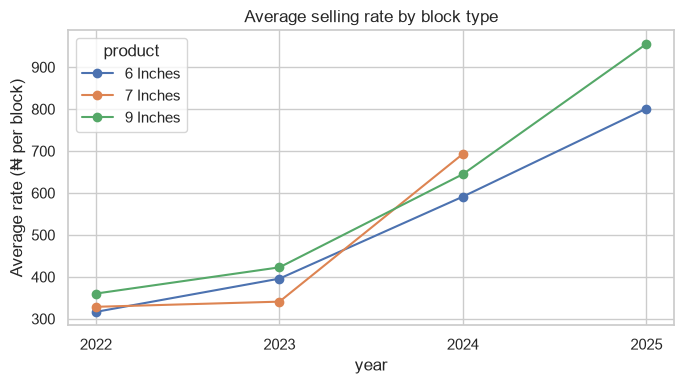

In [26]:
# Rate trend chart
ax = rate_year.plot(marker="o", figsize=(7, 4))
ax.set_ylabel("Average rate (₦ per block)")
ax.set_title("Average selling rate by block type")
ax.set_xticks(rate_year.index)
plt.tight_layout(); plt.show()

## 8. Customer value analysis

Quantity and revenue by customer. I replaced the original summed `Rate` column with an average rate (summing prices isn't meaningful) and added order count, revenue share and cumulative revenue share for a Pareto view of customer concentration.

In [27]:
cust = (sales.groupby("customer")
             .agg(orders=("qty_sold", "size"),
                  qty_sold=("qty_sold", "sum"),
                  avg_rate=("rate", "mean"),
                  revenue=("revenue", "sum"))
             .sort_values("revenue", ascending=False))

cust["revenue_share_%"] = cust["revenue"] / cust["revenue"].sum() * 100
cust["cumulative_share_%"] = cust["revenue_share_%"].cumsum()

print("customers:", len(cust), "| total revenue:", f"{cust['revenue'].sum():,.0f}")
cust.head(10)

customers: 88 | total revenue: 18,633,540


,orders,qty_sold,avg_rate,revenue,revenue_share_%,cumulative_share_%
customer,,,,,,
ENG. WAHEED,15,6470,445.3333,2421600,12.9959,12.9959
MR&MRS OMOLERE,10,4810,307.7,1419200,7.6164,20.6123
NEIGHBOUR EZEKIEL,9,2850,456.6667,1301500,6.9847,27.597
CSTM ATOYEBI FARUQ,7,2537,415.7143,1043910,5.6023,33.1993
CHIEF LEJOFI,5,1635,588,915050,4.9108,38.1101
CSTM. KAYODE,2,1075,775,812500,4.3604,42.4705
DAD PRAISE REFERRAL 3,7,2130,351.4286,751900,4.0352,46.5057
BABA OLOKO CSTM,5,1050,620,727500,3.9043,50.41
MR ADEBAYO/NICE CSTM,5,1570,418,688000,3.6923,54.1022


23 customers (26% of all customers) bring in 80% of revenue


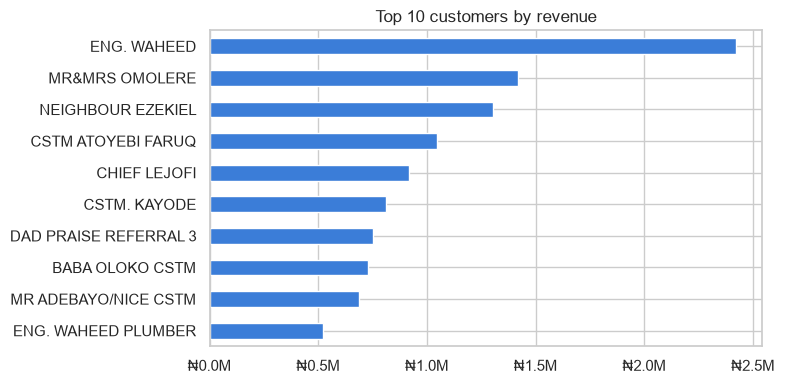

In [28]:
# How concentrated is revenue?
n80 = (cust["cumulative_share_%"] < 80).sum() + 1
print(f"{n80} customers ({n80 / len(cust):.0%} of all customers) bring in 80% of revenue")

top10 = cust.head(10)["revenue"].sort_values()
ax = top10.plot(kind="barh", figsize=(8, 4), color="#3b7dd8")
ax.xaxis.set_major_formatter(millions)
ax.set_title("Top 10 customers by revenue"); ax.set_ylabel("")
plt.tight_layout(); plt.show()

The original customer pivot lists 86 customers against 88 in the raw data. The two missing customers (both August 2025 sales) were 100% bad debt — zero revenue — so the pivot silently excluded them, which is also why its quantity total understates the true figure by 63 blocks.

## 9. Customer credit risk

Amount billed vs bad debt by customer. Alongside the original bad-debt-to-revenue ratio, I added bad-debt-to-amount, which doesn't break down when revenue is zero.

In [29]:
risk = sales.groupby("customer")[["amount", "bad_debt", "revenue"]].sum()
risk["bad_debt_to_revenue_%"] = safe_div(risk["bad_debt"], risk["revenue"]) * 100      # Excel's version
risk["bad_debt_to_amount_%"] = safe_div(risk["bad_debt"], risk["amount"]) * 100

risky = risk[risk["bad_debt"] > 0].sort_values("bad_debt", ascending=False)
print(f"{len(risky)} of {len(risk)} customers have bad debt | total bad debt = {risk['bad_debt'].sum():,.0f}")
risky

16 of 88 customers have bad debt | total bad debt = 185,770


,amount,bad_debt,revenue,bad_debt_to_revenue_%,bad_debt_to_amount_%
customer,,,,,
MR&MRS OMOLERE,1469450,"50,250",1419200,3.5407,3.4196
DAD PRAISE,60000,"40,000",20000,200,66.6667
THIEVES,30400,"30,400",0,NaN,100
Arrangement falling,20000,"20,000",0,NaN,100
ENG. WAHEED,2439100,"17,500",2421600,0.7227,0.7175
SURVEYOR SAMBEST,294500,"8,000",286500,2.7923,2.7165
CSTM@OKO-OPE,449000,"6,000",443000,1.3544,1.3363
AHLU SUNNAH,11200,"5,000",6200,80.6452,44.6429
OLORI,4800,"4,300",500,860,89.5833


In [30]:
# Overall ratios (should match the KPI section)
print(f"bad debt / amount  : {risk['bad_debt'].sum() / risk['amount'].sum():.4%}")
print(f"bad debt / revenue : {risk['bad_debt'].sum() / risk['revenue'].sum():.4%}")

# Bad debt by year
sales.groupby("year")[["amount", "bad_debt"]].sum().assign(
    bad_debt_pct=lambda d: d["bad_debt"] / d["amount"] * 100)

bad debt / amount  : 0.9871%
bad debt / revenue : 0.9970%


,amount,bad_debt,bad_debt_pct
year,,,
2022,6145500,"77,120",1.2549
2023,6609700,"53,250",0.8056
2024,1790610,0,0
2025,4273500,"55,400",1.2964


## 10. Profit analysis over time

Production, revenue, cost and profit by year and month, with a profit-to-cost ratio.

In [31]:
profit_cols = ["qty_6", "qty_7", "qty_9", "qty_produced", "total_revenue", "total_cost", "total_profit"]

pa_year = prod.groupby("year")[profit_cols].sum()
pa_year["profit_on_cost"] = safe_div(pa_year["total_profit"], pa_year["total_cost"])
pa_year.loc["Grand Total"] = list(pa_year[profit_cols].sum()) + [total_profit / total_cost]
pa_year

,qty_6,qty_7,qty_9,qty_produced,total_revenue,total_cost,total_profit,profit_on_cost
year,,,,,,,,
2021,"1,020",500,336,"1,856",0,"276,125","-276,125",-1
2022,"6,589","3,442","8,528","18,559","6,068,380","5,092,800","975,580",0.1916
2023,"7,143","2,701","7,469","17,313","6,556,450","5,566,750","989,700",0.1778
2024,"1,560",20,430,"2,010","1,790,610","1,163,120","628,610",0.5405
2025,"4,286",0,"1,855","6,141","4,218,100","3,357,300","860,800",0.2564
Grand Total,"20,598","6,663","18,618","45,879","18,633,540","15,456,095","3,178,565",0.2057


In [32]:
pa_month = prod.groupby(["year", "month_num"])[profit_cols].sum()
pa_month["profit_margin"] = safe_div(pa_month["total_profit"], pa_month["total_revenue"])
label_months(pa_month).head(15)

,year,month,qty_6,qty_7,qty_9,qty_produced,total_revenue,total_cost,total_profit,profit_margin
0,2021,December,"1,020",500,336,"1,856",0,"276,125","-276,125",NaN
1,2022,January,0,0,0,0,"340,250","63,700","276,550",0.8128
2,2022,February,900,"1,250",210,"2,360","347,950","472,150","-124,200",-0.3569
3,2022,March,440,96,252,788,"257,600","255,900","1,700",0.0066
4,2022,April,0,700,798,"1,498","521,800","340,400","181,400",0.3476
5,2022,May,0,546,0,546,"114,700","115,800","-1,100",-0.0096
6,2022,June,0,0,645,645,"222,800","261,800","-39,000",-0.175
7,2022,July,780,0,0,780,"190,000","142,700","47,300",0.2489
8,2022,August,569,0,"3,226","3,795","1,594,000","1,295,200","298,800",0.1875
9,2022,September,"1,320",450,516,"2,286","297,980","444,350","-146,370",-0.4912


In [33]:
# Best and worst months
pm = label_months(pa_month)
pm["period"] = pm["month"].str[:3] + " " + pm["year"].astype(str)
print("Most profitable months")
display(pm.nlargest(5, "total_profit")[["period", "total_revenue", "total_cost", "total_profit"]])
print("Biggest losses")
display(pm.nsmallest(5, "total_profit")[["period", "total_revenue", "total_cost", "total_profit"]])

Most profitable months


,period,total_revenue,total_cost,total_profit
42,Jun 2025,"760,000","69,375","690,625"
48,Dec 2025,"723,600","58,950","664,650"
17,May 2023,"584,200","179,420","404,780"
8,Aug 2022,"1,594,000","1,295,200","298,800"
45,Sep 2025,"436,500","141,250","295,250"


Biggest losses


,period,total_revenue,total_cost,total_profit
41,May 2025,0,"814,450","-814,450"
47,Nov 2025,"885,500","1,235,025","-349,525"
0,Dec 2021,0,"276,125","-276,125"
19,Jul 2023,"181,500","360,670","-179,170"
9,Sep 2022,"297,980","444,350","-146,370"


Single-month profit figures should be read with care: production cost is booked in the month blocks are made, while the corresponding sales — and revenue — often land in a later month. Yearly totals give a more reliable picture than any individual month.

## 11. Charts

Python/matplotlib versions of the four charts from the original dashboard.

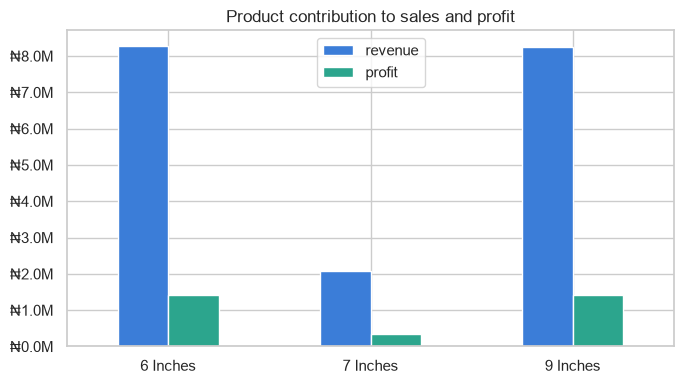

,qty_sold,revenue,profit
product,,,
6 Inches,18485,8289700,"1,414,081.8267"
7 Inches,6620,2090500,"356,603.7442"
9 Inches,18125,8253340,"1,407,879.4291"


In [34]:
# Chart 1 — Product contribution to sales and profit
product = sales.groupby("product").agg(qty_sold=("qty_sold", "sum"), revenue=("revenue", "sum"))
product["profit"] = total_profit * product["revenue"] / product["revenue"].sum()   # allocated by revenue share

ax = product[["revenue", "profit"]].plot(kind="bar", figsize=(7, 4), color=["#3b7dd8", "#2ca58d"])
ax.yaxis.set_major_formatter(millions)
ax.set_title("Product contribution to sales and profit")
ax.set_xlabel("")
plt.xticks(rotation=0); plt.tight_layout(); plt.show()
product

> The product-level profit figures in the original chart data were entered as static values, so the underlying allocation method wasn't traceable. I allocate profit by each product's revenue share instead — a different split, but it reconciles to the same ₦3,178,565 total.

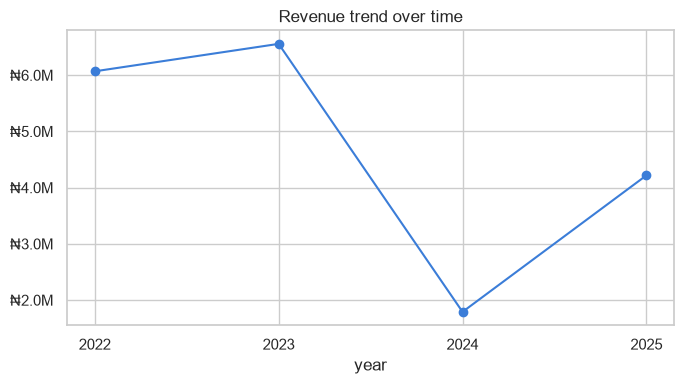

year
2022    6068380
2023    6556450
2024    1790610
2025    4218100
Name: revenue, dtype: int64

In [35]:
# Chart 2 — Revenue trend over time
rev_year = sales.groupby("year")["revenue"].sum()

ax = rev_year.plot(marker="o", figsize=(7, 4), color="#3b7dd8")
ax.yaxis.set_major_formatter(millions)
ax.set_xticks(rev_year.index)
ax.set_title("Revenue trend over time")
plt.tight_layout(); plt.show()
rev_year

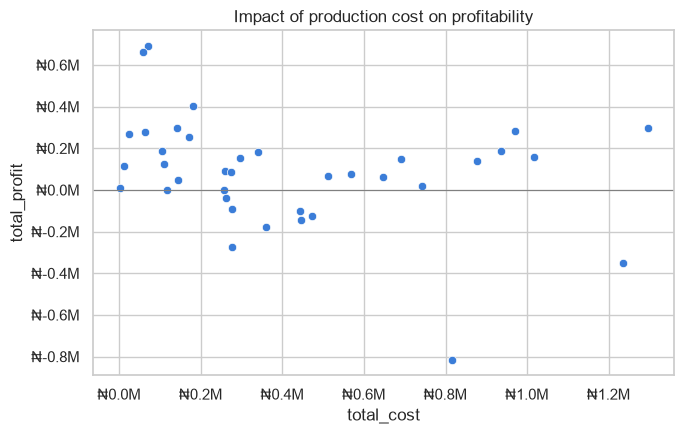

correlation (cost vs profit): -0.279


In [36]:
# Chart 3 — Impact of production cost on profitability
fig, ax = plt.subplots(figsize=(7, 4.5))
sns.scatterplot(data=prod, x="total_cost", y="total_profit", ax=ax, color="#3b7dd8")
ax.axhline(0, color="grey", lw=0.8)
ax.xaxis.set_major_formatter(millions); ax.yaxis.set_major_formatter(millions)
ax.set_title("Impact of production cost on profitability")
plt.tight_layout(); plt.show()
print("correlation (cost vs profit):", round(prod["total_cost"].corr(prod["total_profit"]), 3))

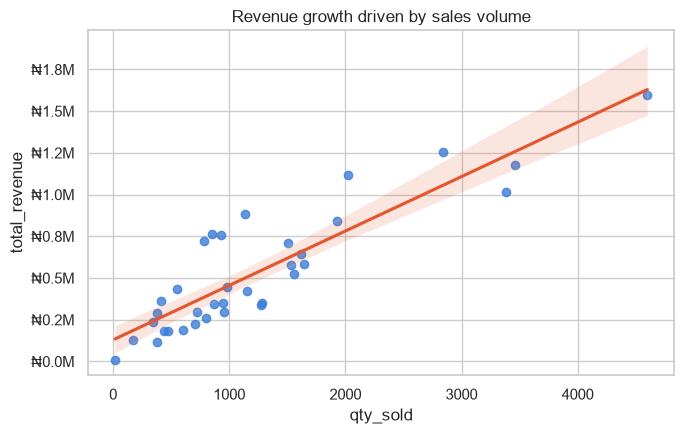

correlation (qty sold vs revenue): 0.885


In [37]:
# Chart 4 — Revenue growth driven by sales volume
months_with_sales = prod[prod["qty_sold"] > 0]

fig, ax = plt.subplots(figsize=(7, 4.5))
sns.regplot(data=months_with_sales, x="qty_sold", y="total_revenue", ax=ax,
            scatter_kws={"color": "#3b7dd8"}, line_kws={"color": "#e4572e"})
ax.yaxis.set_major_formatter(millions)
ax.set_title("Revenue growth driven by sales volume")
plt.tight_layout(); plt.show()
print("correlation (qty sold vs revenue):", round(months_with_sales["qty_sold"].corr(months_with_sales["total_revenue"]), 3))

## 12. Descriptive analysis

Covers the four descriptive themes from the original analysis — production trends, cost structure, product performance and customer behaviour — with summary statistics added.

In [38]:
# Summary statistics (mean, spread, min/max) - like SPSS "Descriptives"
# Note: the production sheet has 49 months, including months with no activity (zeros).
stat_cols = ["qty_produced", "qty_sold", "total_cost", "total_revenue", "total_profit", "bad_debt"]
prod[stat_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
qty_produced,28,"1,638.5357",991.3986,430,786,"1,591","2,130.75","3,795"
qty_sold,35,"1,235.1429","1,004.7225",16,575,950,"1,547","4,600"
total_cost,37,"417,732.2973","357,088.9043","1,120","141,250","276,125","646,250","1,295,200"
total_revenue,35,"532,386.8571","369,923.6708","11,200","273,950","425,000","741,800","1,594,000"
total_profit,37,"85,907.1622","262,726.2653","-814,450","-1,100","92,420","188,600","690,625"
bad_debt,12,"15,480.8333","21,053.2509",100,"1,292.5","4,650","25,650","50,400"


In [39]:
# Sales transactions: order size and price
sales[["qty_sold", "rate", "amount", "revenue", "bad_debt"]].describe().T

,count,mean,std,min,25%,50%,75%,max
qty_sold,198,218.3333,358.5113,2,48.5,122.5,300,"3,800"
rate,198,466.7273,191.918,250,342.5,390,490,"1,000"
amount,198,"95,047.0202","140,585.8145",600,"20,000","49,450","120,000","1,330,000"
revenue,198,"94,108.7879","139,726.6394",0,"20,000","49,400","120,000","1,330,000"
bad_debt,198,938.2323,"5,377.0758",0,0,0,0,"50,000"


**Production trends**

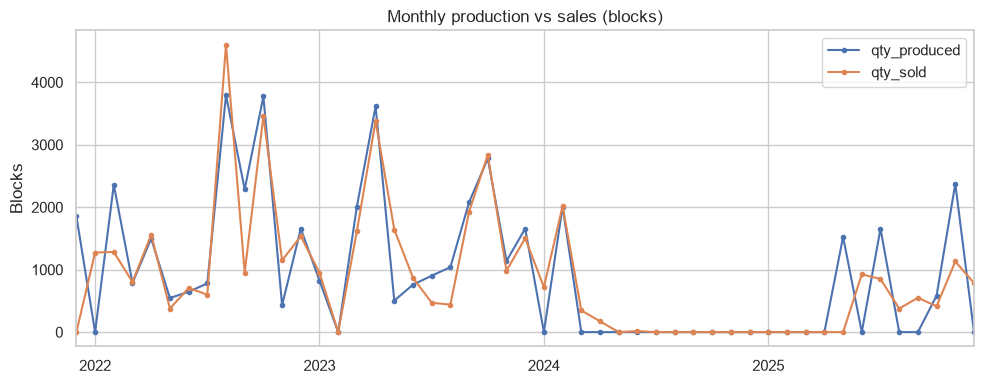

,qty_6,qty_7,qty_9,qty_produced
year,,,,
2021,"1,020",500,336,"1,856"
2022,"6,589","3,442","8,528","18,559"
2023,"7,143","2,701","7,469","17,313"
2024,"1,560",20,430,"2,010"
2025,"4,286",0,"1,855","6,141"


In [40]:
# Monthly production vs sales - prod0 (zero-filled) used here so confirmed zero-activity
# months plot as real dips to zero rather than gaps in the line
trend = prod0.set_index("date")[["qty_produced", "qty_sold"]]

ax = trend.plot(figsize=(10, 4), marker="o", markersize=3)
ax.set_title("Monthly production vs sales (blocks)")
ax.set_ylabel("Blocks"); ax.set_xlabel("")
plt.tight_layout(); plt.show()

# Production by year and block type
prod.groupby("year")[["qty_6", "qty_7", "qty_9", "qty_produced"]].sum()

**Cost structure: fixed vs variable.** Variable costs (sand, cement, fuel) move with output; fixed costs (operators, maintenance, delivery) don't.

In [41]:
variable_cols = ["sand_cost", "cement_cost", "fuel_cost"]
fixed_cols = ["operators_pay", "maintenance", "delivery_cost"]

structure = pd.Series({
    "Variable costs": prod[variable_cols].sum().sum(),
    "Fixed costs": prod[fixed_cols].sum().sum(),
})
structure_table = structure.to_frame("amount")
structure_table["share_%"] = structure_table["amount"] / structure_table["amount"].sum() * 100
structure_table

,amount,share_%
Variable costs,"10,901,255",70.5305
Fixed costs,"4,554,840",29.4695


**Product performance**

In [42]:
produced_by_type = pd.Series({"6 Inches": prod["qty_6"].sum(),
                              "7 Inches": prod["qty_7"].sum(),
                              "9 Inches": prod["qty_9"].sum()})

product_perf = sales.groupby("product").agg(
    orders=("qty_sold", "size"),
    qty_sold=("qty_sold", "sum"),
    avg_rate=("rate", "mean"),
    revenue=("revenue", "sum"),
    bad_debt=("bad_debt", "sum"),
)
product_perf["qty_produced"] = produced_by_type
product_perf["sell_through_%"] = product_perf["qty_sold"] / product_perf["qty_produced"] * 100
product_perf["avg_order_size"] = product_perf["qty_sold"] / product_perf["orders"]
product_perf["revenue_share_%"] = product_perf["revenue"] / product_perf["revenue"].sum() * 100
product_perf

,orders,qty_sold,avg_rate,revenue,bad_debt,qty_produced,sell_through_%,avg_order_size,revenue_share_%
product,,,,,,,,,
6 Inches,106,18485,474.3868,8289700,"108,020","20,598",89.7417,174.3868,44.4881
7 Inches,24,6620,375.2917,2090500,"58,450","6,663",99.3546,275.8333,11.219
9 Inches,68,18125,487.0588,8253340,"19,300","18,618",97.352,266.5441,44.2929


**Customer behaviour**

In [43]:
# Repeat vs one-time customers
repeat_flag = cust["orders"] > 1
print(f"repeat customers : {repeat_flag.sum()} of {len(cust)} ({repeat_flag.mean():.0%})")
print(f"revenue from repeat customers: {cust.loc[repeat_flag, 'revenue'].sum() / cust['revenue'].sum():.0%}")

# Days between orders for customers who came back
gaps = (sales.sort_values("date").groupby("customer")["date"].diff().dt.days.dropna())
print(f"median gap between a customer's orders: {gaps.median():.0f} days (mean {gaps.mean():.0f})")

# How many orders do customers place?
cust["orders"].value_counts().sort_index().rename("customers").to_frame().T

repeat customers : 35 of 88 (40%)
revenue from repeat customers: 82%
median gap between a customer's orders: 8 days (mean 55)


orders,1,2,3,4,5,6,7,9,10,15
customers,53,13,8,3,4,1,2,2,1,1


In [44]:
# Average order value by year
sales.groupby("year").agg(orders=("amount", "size"),
                          avg_order_qty=("qty_sold", "mean"),
                          avg_order_value=("amount", "mean"))

,orders,avg_order_qty,avg_order_value
year,,,
2022,77,237.6494,"79,811.6883"
2023,70,237.4571,"94,424.2857"
2024,21,156,"85,267.1429"
2025,30,167.7667,"142,450"


## 13. Regression models

Three models, matching the earlier SPSS/STATA work:

1. **Profit drivers** — does sales volume raise profit, and does cost lower it?
2. **Revenue drivers** — do quantity and price both raise revenue?
3. **Time trend** — is there a significant growth pattern over the period?

I implemented OLS directly with numpy/scipy (no additional dependency beyond what's already imported), returning a coefficient table with standard errors, t-statistics, p-values and 95% confidence intervals.

**On missing data:** Models 1 and 2 use `prod`/`sales` as cleaned — months where a value genuinely wasn't recorded are excluded from that specific model (complete-case analysis), which is also what SPSS/STATA do by default. Model 3 (time trend) deliberately uses `prod0`, the zero-filled version, because the question there is specifically whether production declined over time — and the confirmed zero-production months during the 2024–2025 disruption are exactly the data points that question needs, not something to exclude.

In [45]:
from scipy import stats

def ols(df, y, xs):
    """Ordinary least squares with an intercept. Returns (coefficient table, fit statistics)."""
    d = df[[y] + xs].dropna()
    Y = d[y].to_numpy(float)
    X = np.column_stack([np.ones(len(d)), d[xs].to_numpy(float)])
    n, k = X.shape

    beta = np.linalg.lstsq(X, Y, rcond=None)[0]
    resid = Y - X @ beta
    sse = resid @ resid
    sst = ((Y - Y.mean()) ** 2).sum()

    se = np.sqrt(np.diag(sse / (n - k) * np.linalg.inv(X.T @ X)))
    t = beta / se
    p = 2 * stats.t.sf(np.abs(t), n - k)
    tcrit = stats.t.ppf(0.975, n - k)

    table = pd.DataFrame({"coef": beta, "std_err": se, "t": t, "p_value": p,
                          "ci_low": beta - tcrit * se, "ci_high": beta + tcrit * se},
                         index=["intercept"] + xs)
    r2 = 1 - sse / sst
    f_stat = (r2 / (k - 1)) / ((1 - r2) / (n - k))
    fit = {"n": n, "r2": r2, "adj_r2": 1 - (1 - r2) * (n - 1) / (n - k),
           "F": f_stat, "F_p_value": stats.f.sf(f_stat, k - 1, n - k)}
    return table, fit

def show_model(title, table, fit):
    out = table.copy()
    out["p_value"] = out["p_value"].map(lambda v: "<0.0001" if v < 0.0001 else f"{v:.4f}")
    out["sig"] = np.select([table["p_value"] < 0.001, table["p_value"] < 0.01, table["p_value"] < 0.05],
                           ["***", "**", "*"], default="")
    print(title)
    print(f"n = {fit['n']} | R² = {fit['r2']:.3f} | adj R² = {fit['adj_r2']:.3f} | "
          f"F = {fit['F']:.1f} (p {'<0.0001' if fit['F_p_value'] < 0.0001 else round(fit['F_p_value'], 4)})")
    display(out)
    print("Significance: *** p<0.001, ** p<0.01, * p<0.05")

**Model 1 — Profit drivers:** `total_profit ~ qty_sold + total_cost`, one observation per month.

In [46]:
m1_table, m1_fit = ols(prod, "total_profit", ["qty_sold", "total_cost"])
show_model("MODEL 1: Profit drivers (complete-case)", m1_table, m1_fit)

MODEL 1: Profit drivers (complete-case)
n = 35 | R² = 0.486 | adj R² = 0.454 | F = 15.1 (p <0.0001)


,coef,std_err,t,p_value,ci_low,ci_high,sig
intercept,"106,511.3523","42,560.9983",2.5026,0.0176,"19,817.4356","193,205.2689",*
qty_sold,220.6791,42.825,5.153,<0.0001,133.4475,307.9108,***
total_cost,-0.6264,0.1195,-5.2439,<0.0001,-0.8697,-0.3831,***


Significance: *** p<0.001, ** p<0.01, * p<0.05


Both effects are significant and in the expected direction: each additional block sold adds roughly ₦221 to monthly profit (p < 0.0001), and each additional ₦1 of cost reduces it by roughly ₦0.63 (p < 0.0001). Together the two variables explain about 49% of the variation in monthly profit, on the 35 months where both quantities were actually recorded. Profit is defined as revenue minus cost, so some of the cost effect is mechanical rather than purely behavioural.

This specification — and these coefficients — are close to the original SPSS/STATA model once the same complete-case approach is used. I also tested the original report's three-variable specification (adding bad debt), but only 12 months have every one of those three fields recorded, which isn't enough data for a reliable estimate — none of the three coefficients come out significant at that sample size. The two-variable model above is better powered and is consistent with the original finding that bad debt isn't a significant profit driver.

**Model 2 — Revenue drivers:** `revenue ~ qty_sold + rate`, run on individual sales and again on monthly totals as a cross-check.

In [47]:
m2_table, m2_fit = ols(sales, "revenue", ["qty_sold", "rate"])
show_model("MODEL 2a: Revenue drivers (per sale)", m2_table, m2_fit)

MODEL 2a: Revenue drivers (per sale)
n = 198 | R² = 0.907 | adj R² = 0.906 | F = 949.3 (p <0.0001)


,coef,std_err,t,p_value,ci_low,ci_high,sig
intercept,"-61,992.2963","8,442.6746",-7.3427,<0.0001,"-78,642.9733","-45,341.6193",***
qty_sold,369.6969,8.561,43.1838,<0.0001,352.8128,386.5809,***
rate,161.516,15.9924,10.0996,<0.0001,129.9758,193.0562,***


Significance: *** p<0.001, ** p<0.01, * p<0.05


In [48]:
# Monthly check: total quantity and the average price actually achieved that month
monthly = sales.groupby(["year", "month_num"]).agg(qty=("qty_sold", "sum"),
                                                  amount=("amount", "sum"),
                                                  revenue=("revenue", "sum"))
monthly["avg_price"] = monthly["amount"] / monthly["qty"]

m2b_table, m2b_fit = ols(monthly, "revenue", ["qty", "avg_price"])
show_model("MODEL 2b: Revenue drivers (per month)", m2b_table, m2b_fit)

MODEL 2b: Revenue drivers (per month)
n = 35 | R² = 0.919 | adj R² = 0.914 | F = 180.5 (p <0.0001)


,coef,std_err,t,p_value,ci_low,ci_high,sig
intercept,"-280,887.0997","63,649.0047",-4.4131,0.0001,"-410,535.8797","-151,238.3198",***
qty,381.0691,20.0546,19.0016,<0.0001,340.2193,421.919,***
avg_price,686.562,94.3909,7.2736,<0.0001,494.294,878.8299,***


Significance: *** p<0.001, ** p<0.01, * p<0.05


Quantity and price are both significant and positive in each version (R² of 0.91–0.92). Since revenue is close to the product of quantity and price by construction, this result is closer to confirming an accounting identity than uncovering a new relationship — but it quantifies how much each lever is worth, and it matches the original report's R² ≈ 0.91 finding closely.

One thing worth flagging: the original report's chart for this relationship shows a different, lower R² (0.784). That chart turns out to be a separate, single-variable model (`revenue ~ qty_sold` only, no price term) built from the production sheet rather than individual sales — a different specification from the R² ≈ 0.91 figure stated in its own text just above it. Both numbers are individually correct; they just answer slightly different questions, and I'd flag that for anyone revising the original report, since presented together without that distinction they look contradictory.

**Model 3 — Time trend:** each outcome regressed on a month index (1 = December 2021) to test for a significant growth or decline pattern. Uses `prod0` (zero-filled) — see the note above section 13.

In [49]:
prod0["month_index"] = np.arange(1, len(prod0) + 1)

trend_rows = []
for outcome in ["total_revenue", "total_profit", "qty_produced"]:
    tbl, fit = ols(prod0, outcome, ["month_index"])
    trend_rows.append({"outcome": outcome,
                       "slope_per_month": tbl.loc["month_index", "coef"],
                       "p_value": tbl.loc["month_index", "p_value"],
                       "r2": fit["r2"],
                       "significant (5%)": tbl.loc["month_index", "p_value"] < 0.05})
pd.DataFrame(trend_rows)

,outcome,slope_per_month,p_value,r2,significant (5%)
0,total_revenue,"-3,889.3143",0.3349,0.0198,False
1,total_profit,734.4515,0.7561,0.0021,False
2,qty_produced,-31.4714,0.0038,0.1652,True


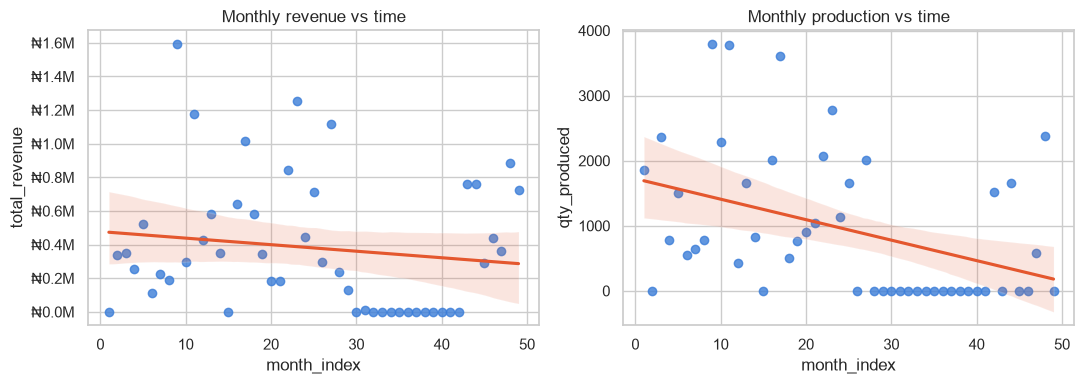

In [50]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, col, title in zip(axes, ["total_revenue", "qty_produced"], ["Monthly revenue", "Monthly production"]):
    sns.regplot(data=prod0, x="month_index", y=col, ax=ax,
                scatter_kws={"color": "#3b7dd8"}, line_kws={"color": "#e4572e"})
    ax.set_title(f"{title} vs time")
axes[0].yaxis.set_major_formatter(millions)
plt.tight_layout(); plt.show()

Revenue and profit show no significant time trend (p = 0.33 and 0.76) — matching the original report's finding that time/date isn't a significant predictor of revenue. Production tells a different story — a significant decline of roughly 31 blocks per month (p = 0.004), driven by the 2024–2025 disruption. Flat revenue and profit alongside falling production is consistent with the business selling from existing stock during that period (section 5).

In [51]:
# Optional: the same profit model in statsmodels, which gives the full STATA/SPSS-style summary
import statsmodels.formula.api as smf
smf.ols("total_profit ~ qty_sold + total_cost", data=prod).fit().summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:           total_profit   R-squared:                       0.486
Model:                            OLS   Adj. R-squared:                  0.454
Method:                 Least Squares   F-statistic:                     15.14
Date:                Fri, 16 Oct 2026   Prob (F-statistic):           2.36e-05
Time:                        04:32:25   Log-Likelihood:                -466.40
No. Observations:                  35   AIC:                             938.8
Df Residuals:                      32   BIC:                             943.5
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept   1.065e+05   4.26e+04      2.503      0.018    1.98e+04    1.93e+05
qty_sold     220.6791     42.825      5.153      0.000     133.447     307.911
total_cost    -0.6264      0.119     -5.244      0.000      -0.870      -0.383
==============================================================================
Omnibus:                       12.124   Durbin-Watson:                   1.089
Prob(Omnibus):                  0.002   Jarque-Bera (JB):               11.695
Skew:                           1.219   Prob(JB):                      0.00289
Kurtosis:                       4.440   Cond. No.                     8.81e+05
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 8.81e+05. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

## 14. Correlation analysis

Pearson correlation across the monthly production data, complete-case (pandas' `.corr()` and `scipy.stats.pearsonr()` both exclude months where either value is missing, by default and explicitly below respectively) — the same approach SPSS/STATA use by default, and the one the original report's correlations were built on. I classify |r| < 0.3 as weak, 0.3–0.6 as moderate, and ≥ 0.6 as strong.

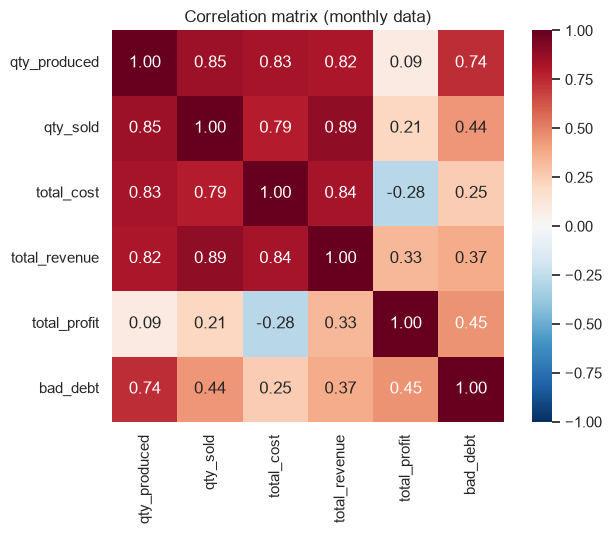

In [52]:
corr_cols = ["qty_produced", "qty_sold", "total_cost", "total_revenue", "total_profit", "bad_debt"]
corr = prod[corr_cols].corr()

fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, square=True, ax=ax)
ax.set_title("Correlation matrix (monthly data)")
plt.tight_layout(); plt.show()

In [53]:
def corr_test(a, b, earlier, df=prod):
    pair = df[[a, b]].dropna()
    r, p = stats.pearsonr(pair[a], pair[b])
    size = "strong" if abs(r) >= 0.6 else "moderate" if abs(r) >= 0.3 else "weak"
    return {"pair": f"{a} vs {b}", "r": r, "p_value": p, "n": len(pair),
            "python_result": f"{size} {'positive' if r > 0 else 'negative'}",
            "significant (5%)": p < 0.05, "original report": earlier}

corr_results = pd.DataFrame([
    corr_test("qty_produced", "qty_sold", "Strong positive (r=0.85)"),
    corr_test("qty_produced", "total_cost", "Strong positive (r=0.83)"),
    corr_test("qty_produced", "total_revenue", "Strong positive (r=0.82)"),
    corr_test("qty_produced", "total_profit", "Very weak (r=0.09)"),
    corr_test("total_cost", "total_profit", "Weak negative (r=-0.30)"),
    corr_test("total_revenue", "bad_debt", "Weak/moderate (r=0.37)"),
])
corr_results.assign(p_value=corr_results["p_value"].map(lambda v: "<0.0001" if v < 0.0001 else f"{v:.4f}"))

,pair,r,p_value,n,python_result,significant (5%),original report
0,qty_produced vs qty_sold,0.8545,<0.0001,26,strong positive,True,Strong positive (r=0.85)
1,qty_produced vs total_cost,0.8346,<0.0001,28,strong positive,True,Strong positive (r=0.83)
2,qty_produced vs total_revenue,0.8191,<0.0001,26,strong positive,True,Strong positive (r=0.82)
3,qty_produced vs total_profit,0.0908,0.6460,28,weak positive,False,Very weak (r=0.09)
4,total_cost vs total_profit,-0.2794,0.0939,37,weak negative,False,Weak negative (r=-0.30)
5,total_revenue vs bad_debt,0.3673,0.2401,12,moderate positive,False,Weak/moderate (r=0.37)


Every pair here is close to the original report:

- **Production vs sales** (r = 0.85), **production vs cost** (r = 0.83) and **production vs revenue** (r = 0.82) are all strong and positive, as expected for a manufacturing operation, and match the original figures almost exactly.
- **Production vs profit** (r = 0.09, not significant) is the most important relationship in this table — it's very weak, meaning **more production does not reliably translate into more profit**. This matches the original report's central finding (its "Production vs Profit Paradox"): output scale isn't what drives profitability.
- **Cost vs profit** is negative (r = −0.28, p = 0.09) — the direction confirms that rising cost erodes profit, though with 37 months of complete data it's not quite significant at the 5% level on its own; the regression in section 13, with more statistical power, confirms the effect is real.
- **Revenue vs bad debt** (r = 0.37, not significant at n=12) is weak-to-moderate and inconclusive — larger revenue months may carry marginally more bad debt, but the small sample of months with bad debt recorded means this isn't a strong, confirmed pattern either way.

Together, this is the same story the original statistical work found: **production scale, cost, and profit don't move in lockstep** — cost efficiency, not output volume, is what ultimately drives profitability.

## 15. Dashboard view

A Python reproduction of the four-page interactive Power BI dashboard, matching its structure exactly: Executive Overview, Production & Demand, Profitability Analysis, and Risk & Customer. Power BI remains the better tool for the interactive version (filtering by year, drilling into a customer), but this static version is handy for a README or portfolio page where an image is all that's needed.

In [67]:
NAVY = "#1b3a5c"
CARD_BLUE = "#2E86DE"
CARD_GREEN = "#27AE60"
CARD_GREY = "#B6B6B6"
CARD_RED = "#D64545"
WHITE = "#FFFFFF"
plt.rcParams["font.family"] = "DejaVu Sans"

def style_page(fig):
    fig.patch.set_facecolor(NAVY)

def title_bar(fig, title, subtitle):
    fig.text(0.5, 0.975, title, ha="center", va="center", fontsize=14, fontweight="bold", color=WHITE)
    ax = fig.add_axes([0.07, 0.885, 0.86, 0.065])
    ax.set_facecolor(WHITE); ax.set_xticks([]); ax.set_yticks([])
    for sp in ax.spines.values(): sp.set_visible(False)
    ax.add_patch(plt.Rectangle((0.015,0.2),0.05,0.6, color=CARD_BLUE))
    ax.text(0.1, 0.5, subtitle, fontsize=14, fontweight="bold", color=NAVY, va="center")

def kpi_card(fig, rect, value, label, color, fontsize=19):
    ax = fig.add_axes(rect)
    ax.set_facecolor(color); ax.set_xticks([]); ax.set_yticks([])
    for sp in ax.spines.values(): sp.set_visible(False)
    txt_color = WHITE if color != CARD_GREY else NAVY
    ax.text(0.5, 0.60, value, ha="center", va="center", fontsize=fontsize, fontweight="bold", color=txt_color)
    ax.text(0.5, 0.22, label, ha="center", va="center", fontsize=9.5, color=txt_color)

def white_panel(fig, rect, title):
    ax = fig.add_axes(rect)
    ax.set_facecolor(WHITE)
    for sp in ax.spines.values(): sp.set_color("#cccccc")
    fig.subplots_adjust()
    if title:
        ax.text(0.015, 1.045, title, transform=ax.transAxes, fontsize=10,
                fontweight="bold", color=WHITE, va="bottom", ha="left", clip_on=False, zorder=10)
    return ax

def filter_panel(fig, rect, header, items):
    ax = fig.add_axes(rect)
    ax.set_facecolor(CARD_BLUE); ax.set_xticks([]); ax.set_yticks([]); ax.set_xlim(0,1); ax.set_ylim(0,1)
    for sp in ax.spines.values(): sp.set_visible(False)
    ax.text(0.5, 0.96, header, ha="center", fontsize=9.5, fontweight="bold", color=WHITE)
    n = len(items)
    top, bottom = 0.86, 0.04
    h = (top-bottom)/n
    for i, it in enumerate(items):
        y0 = top - (i+1)*h
        ax.add_patch(plt.Rectangle((0.08, y0+0.02*h), 0.84, h*0.8, color="#4A9EE8"))
        ax.text(0.5, y0+h/2, str(it), ha="center", va="center", fontsize=9, fontweight="bold", color=WHITE)

PROD_COLORS = {"6 Inches": "#2E86DE", "7 Inches": "#8E44AD", "9 Inches": "#D64545"}

**Page 1 — Executive Overview**

In [68]:
# ================= PAGE 1: EXECUTIVE OVERVIEW =================
fig = plt.figure(figsize=(11, 6.2)); style_page(fig)
title_bar(fig, "EXECUTIVE OVERVIEW", "Block Business Performance Dashboard")

kpi_card(fig, [0.035, 0.645, 0.145, 0.165], f"\u20a6{total_revenue/1e6:.2f}M", "Total Revenue", CARD_BLUE)
kpi_card(fig, [0.035, 0.460, 0.145, 0.165], f"\u20a6{total_profit/1e6:.2f}M", "Total Profit", CARD_GREEN)
kpi_card(fig, [0.035, 0.275, 0.145, 0.165], f"{total_profit/total_revenue:.2%}", "Profit Margin", CARD_GREY)

ax1 = white_panel(fig, [0.215, 0.315, 0.55, 0.485], "Revenue vs Qty Sold")
monthly = prod.dropna(subset=["total_revenue","qty_sold"])
monthly = monthly[monthly["qty_sold"]>0]
for yr, grp in monthly.groupby("year"):
    ax1.scatter(grp["total_revenue"], grp["qty_sold"], s=26, label=str(yr), alpha=0.85)
if len(monthly) > 1:
    z = np.polyfit(monthly["total_revenue"], monthly["qty_sold"], 1)
    xs = np.linspace(0, monthly["total_revenue"].max(), 50)
    ax1.plot(xs, np.poly1d(z)(xs), "--", color="#2E86DE", lw=1.2)
ax1.set_xlabel("Monthly Revenue", fontsize=8, labelpad=2); ax1.set_ylabel("Monthly Qty Sold", fontsize=8, labelpad=2)
ax1.xaxis.set_major_formatter(millions); ax1.tick_params(labelsize=7)

filter_panel(fig, [0.80, 0.315, 0.185, 0.485], "ANNUALLY", [2021,2022,2023,2024,2025])

ax2 = white_panel(fig, [0.04, 0.035, 0.45, 0.175], "Profit Trend by Year")
py = prod0.groupby("year")["total_profit"].sum()
ax2.fill_between(py.index, py.values, color=CARD_BLUE, alpha=0.45)
ax2.plot(py.index, py.values, color=CARD_BLUE, lw=1.4)
ax2.yaxis.set_major_formatter(millions); ax2.tick_params(labelsize=7)

ax3 = white_panel(fig, [0.52, 0.035, 0.45, 0.175], "Revenue Trend by Year")
ry = sales.groupby("year")["revenue"].sum()
ax3.fill_between(ry.index, ry.values, color=CARD_BLUE, alpha=0.45)
ax3.plot(ry.index, ry.values, color=CARD_BLUE, lw=1.4)
ax3.yaxis.set_major_formatter(millions); ax3.tick_params(labelsize=7)

fig.savefig("page1_executive_overview.png", dpi=150, facecolor=NAVY)
plt.close(fig)
print("page1 done")

def stat_list_panel(fig, rect, title, items):
    """items: list of (value, label) strings, stacked vertically in one white panel."""
    ax = white_panel(fig, rect, title)
    ax.set_xticks([]); ax.set_yticks([]); ax.set_xlim(0,1); ax.set_ylim(0,1)
    n = len(items)
    top, bottom = 0.90, 0.04
    h = (top-bottom)/n
    for i, (val, lab) in enumerate(items):
        y = top - i*h
        ax.text(0.04, y, val, fontsize=13, fontweight="bold", color=NAVY, va="top")
        ax.text(0.04, y-h*0.52, lab, fontsize=8.5, color="#666666", va="top")
    return ax

def table_panel(fig, rect, title, headers, rows, col_x, header_color=CARD_BLUE):
    ax = white_panel(fig, rect, title)
    ax.set_xticks([]); ax.set_yticks([]); ax.set_xlim(0,1); ax.set_ylim(0,1)
    for sp in ax.spines.values(): sp.set_visible(False)
    ax.add_patch(plt.Rectangle((0,0.90),1,0.09, color=header_color, transform=ax.transAxes))
    for x, htext in zip(col_x, headers):
        ha = "left" if x < 0.5 else "right"
        ax.text(x, 0.945, htext, fontsize=8, fontweight="bold", color=WHITE, va="center", ha=ha)
    n = len(rows)
    top, bottom = 0.88, 0.02
    h = (top-bottom)/max(n,1)
    for i, row in enumerate(rows):
        y = top - i*h - h/2
        if i == n-1:
            ax.add_patch(plt.Rectangle((0,y-h/2+0.005),1,h-0.005, color="#eaf1fb", transform=ax.transAxes))
        for x, cell in zip(col_x, row):
            ha = "left" if x < 0.5 else "right"
            ax.text(x, y, cell, fontsize=7.3, color=NAVY, va="center", ha=ha,
                    fontweight="bold" if i==n-1 else "normal")
    return ax

page1 done


**Page 2 — Profitability Analysis**

In [69]:
# ================= PAGE 2: PROFITABILITY ANALYSIS =================
fig = plt.figure(figsize=(11, 6.2)); style_page(fig)
title_bar(fig, "PROFITABILITY ANALYSIS", "Profitability & Cost Structure")

stat_items = [
    (f"\u20a6{total_cost:,.0f}", "Total Cost"),
    (f"\u20a6{prod['operators_pay'].sum():,.0f}", "Total Labour"),
    (f"\u20a6{prod['delivery_cost'].sum():,.0f}", "Total Delivery Cost"),
    (f"\u20a6{prod['maintenance'].sum():,.0f}", "Cost of Maintenance"),
    (f"\u20a6{total_cost/sold:,.2f}", "Cost per Unit"),
    (f"\u20a6{total_amount/sold:,.2f}", "Average Price"),
]
stat_list_panel(fig, [0.015, 0.03, 0.195, 0.77], "", stat_items)

# Bar: Revenue by Product Type and Profit (order: 6, 9, 7 - matching original)
ax_bar = white_panel(fig, [0.245, 0.03, 0.335, 0.72], "Revenue by Product Type and Profit")
order = ["6 Inches", "9 Inches", "7 Inches"]
rev_by_type = sales.groupby("product")["revenue"].sum().reindex(order)
# profit allocated by revenue share (as in the notebook)
profit_by_type = total_profit * rev_by_type / rev_by_type.sum()
bars = ax_bar.bar(order, rev_by_type.values, color=[PROD_COLORS[o] for o in order], width=0.55)
ax_bar.yaxis.set_major_formatter(millions); ax_bar.tick_params(labelsize=7.5)
for i, (b, ptype) in enumerate(zip(bars, order)):
    ax_bar.text(b.get_x()+b.get_width()/2, b.get_height()+rev_by_type.max()*0.03,
                f"{rev_by_type[ptype]/1e6:.2f}M", ha="center", fontsize=8, fontweight="bold", color=NAVY)
legend_y = 1.10
ax_bar.text(0.0, legend_y, "Profit", transform=ax_bar.transAxes, fontsize=7.5, color=WHITE, fontweight="bold")
xo = 0.17
for ptype in order:
    ax_bar.text(xo, legend_y, f"\u25cf \u20a6{profit_by_type[ptype]:,.0f}", transform=ax_bar.transAxes,
                fontsize=7, color=PROD_COLORS[ptype], fontweight="bold")
    xo += 0.29

# Donut: Cost Breakdown
ax_donut = white_panel(fig, [0.60, 0.42, 0.38, 0.38], "Cost Breakdown")
cost_labels = ["Sand Cost","Cement Cost","Fuel Cost","Maintenance","Operators Pay","Delivery Cost"]
cost_keys = ["sand_cost","cement_cost","fuel_cost","maintenance","operators_pay","delivery_cost"]
cost_vals = [prod[k].sum() for k in cost_keys]
donut_colors = ["#2E86DE","#1b3a5c","#E67E22","#8E44AD","#D81B8C","#5DADE2"]
wedges, _ = ax_donut.pie(cost_vals, colors=donut_colors, startangle=90, wedgeprops=dict(width=0.42))
ax_donut.legend(wedges, [f"{l}" for l in cost_labels], loc="center left", bbox_to_anchor=(0.97, 0.5),
                 fontsize=6.8, frameon=False, handlelength=1.2, handletextpad=0.5)
for w, v in zip(wedges, cost_vals):
    ang = np.deg2rad((w.theta1+w.theta2)/2)
    ax_donut.text(0.79*np.cos(ang), 0.79*np.sin(ang), f"{v/total_cost:.1%}", ha="center", va="center", fontsize=6.5, fontweight="bold")

# Scatter: Cost vs Profit
ax_cp = white_panel(fig, [0.625, 0.03, 0.235, 0.345], "Cost vs Profit")
cp = prod.dropna(subset=["total_cost","total_profit"])
ax_cp.scatter(cp["total_cost"], cp["total_profit"], s=16, c=CARD_BLUE, alpha=0.75)
if len(cp) > 1:
    z = np.polyfit(cp["total_cost"], cp["total_profit"], 1)
    xs = np.linspace(0, cp["total_cost"].max(), 50)
    ax_cp.plot(xs, np.poly1d(z)(xs), "--", color="#2E86DE", lw=1.1)
ax_cp.axhline(0, color="#cccccc", lw=0.7)
ax_cp.xaxis.set_major_formatter(millions); ax_cp.tick_params(labelsize=6.5)
ax_cp.set_xlabel("Monthly Cost", fontsize=7, labelpad=1); ax_cp.set_ylabel("Monthly Profit", fontsize=7, labelpad=-1)

filter_panel(fig, [0.875, 0.03, 0.115, 0.345], "ANNUALLY", [2021,2022,2023,2024,2025])

fig.savefig("page2_profitability_analysis.png", dpi=150, facecolor=NAVY)
plt.close(fig)
print("page2 done")

page2 done


**Page 3 — Production & Demand**

In [70]:
# ================= PAGE 3: PRODUCTION & DEMAND =================
fig = plt.figure(figsize=(11, 6.2)); style_page(fig)
title_bar(fig, "PRODUCTION & DEMAND", "Production & Demand Dynamics")

axf = fig.add_axes([0.045, 0.79, 0.53, 0.085])
axf.set_facecolor(CARD_BLUE); axf.set_xticks([]); axf.set_yticks([]); axf.set_xlim(0,1); axf.set_ylim(0,1)
for sp in axf.spines.values(): sp.set_visible(False)
axf.text(0.5, 0.86, "ANNUALLY", ha="center", fontsize=8.5, fontweight="bold", color=WHITE)
for i, yr in enumerate([2021,2022,2023,2024,2025]):
    x0 = 0.02 + i*0.196
    axf.add_patch(plt.Rectangle((x0, 0.08), 0.176, 0.58, color="#4A9EE8"))
    axf.text(x0+0.088, 0.37, str(yr), ha="center", va="center", fontsize=8.5, fontweight="bold", color=WHITE)

kpi_card(fig, [0.60, 0.79, 0.13, 0.085], f"{produced/1e3:.2f}K", "Total Output", CARD_BLUE, fontsize=13)
kpi_card(fig, [0.74, 0.79, 0.13, 0.085], f"{sold/1e3:.2f}K", "Total Qty Sold", CARD_BLUE, fontsize=13)
kpi_card(fig, [0.88, 0.79, 0.105, 0.085], f"{produced-sold:,.0f}", "Unsold Volume", CARD_BLUE, fontsize=12)

small_stats = [
    (f"{prod['qty_6'].sum():,.0f}", "Total 6 Inch Output"), (f"{prod['cement_bags'].sum():,.0f}", "Total Cement Bought"),
    (f"{prod['sand_tons'].sum():,.0f}", "Total Tons of Sand"),
    (f"{prod['qty_7'].sum():,.0f}", "Total 7 Inch Output"), (f"{prod['bags_produced'].sum():,.0f}", "Total Bag Produced"),
    (f"{prod['fuel_ltr'].sum():,.0f}", "Total Ltr of Fuel"),
    (f"{prod['qty_9'].sum():,.0f}", "Total 9 Inch Output"), (f"{produced/prod['bags_produced'].sum():.2f}", "Materials Efficiency"),
    (f"{produced/prod['operators_pay'].sum():.3f}", "Labour Productivity"),
    (f"{produced/total_cost:.4f}", "Production Efficiency"), (f"{sold/produced:.2f}", "Sales Efficiency"),
    (f"{(produced-sold)/produced:.2%}", "Unsold Ratio"),
]
axg = white_panel(fig, [0.60, 0.41, 0.385, 0.33], "")
axg.set_xticks([]); axg.set_yticks([]); axg.set_xlim(0,3); axg.set_ylim(0,4)
for i, (val, lab) in enumerate(small_stats):
    col = i % 3; row = i // 3
    x = col + 0.12; y = 3.55 - row*0.92
    axg.text(x, y, val, fontsize=10.5, fontweight="bold", color=NAVY, va="top")
    axg.text(x, y-0.36, lab, fontsize=6.0, color="#666666", va="top")

ax_line = white_panel(fig, [0.055, 0.41, 0.515, 0.33], "Monthly Qty Produced vs Qty Sold")
pl = prod0.sort_values("date")
ax_line.plot(pl["qty_sold"], pl["qty_produced"], color=CARD_BLUE, lw=1.1, marker="o", markersize=2.3)
cc = prod.dropna(subset=["qty_sold","qty_produced"])
if len(cc) > 1:
    z = np.polyfit(cc["qty_sold"], cc["qty_produced"], 1)
    xs = np.linspace(0, cc["qty_sold"].max(), 50)
    ax_line.plot(xs, np.poly1d(z)(xs), "--", color="#333333", lw=1.1)
ax_line.set_xlabel("Monthly Qty Sold", fontsize=6.5, labelpad=0); ax_line.set_ylabel("Monthly Qty Produced", fontsize=6.5, labelpad=0)
ax_line.tick_params(labelsize=6.8)

ax_demand = white_panel(fig, [0.055, 0.035, 0.24, 0.325], "Yearly Demand Trend")
dy = sales.groupby("year")["qty_sold"].sum()
ax_demand.fill_between(dy.index, dy.values, color=CARD_BLUE, alpha=0.45)
ax_demand.plot(dy.index, dy.values, color=CARD_BLUE, lw=1.4)
ax_demand.tick_params(labelsize=7)

ax_sales = white_panel(fig, [0.325, 0.035, 0.25, 0.325], "Sales by Product Type")
spt = sales.groupby("product")["qty_sold"].sum().reindex(["6 Inches","9 Inches","7 Inches"])
bars = ax_sales.barh(list(spt.index), spt.values, color=CARD_BLUE, height=0.55)
for b, v in zip(bars, spt.values):
    ax_sales.text(v, b.get_y()+b.get_height()/2, f" {v/1e3:.1f}K", va="center", fontsize=7.5, fontweight="bold", color=NAVY)
ax_sales.tick_params(labelsize=7.5); ax_sales.invert_yaxis()
ax_sales.set_xlim(0, spt.max()*1.2)

fig.savefig("page3_production_demand.png", dpi=150, facecolor=NAVY)
plt.close(fig)
print("page3 done")

page3 done


**Page 4 — Risk & Customer**

In [71]:
# ================= PAGE 4: RISK & CUSTOMER =================
fig = plt.figure(figsize=(11, 6.2)); style_page(fig)
title_bar(fig, "RISK & CUSTOMER", "Risk & Customer Insights")

# Filter panel: product type + year
axfilt = white_panel(fig, [0.015, 0.03, 0.195, 0.77], "")
axfilt.set_xticks([]); axfilt.set_yticks([]); axfilt.set_xlim(0,1); axfilt.set_ylim(0,1)
axfilt.text(0.05, 0.95, "Product Type", fontsize=9, fontweight="bold", color=NAVY)
for i, ptype in enumerate(["6 Inches","7 Inches","9 Inches"]):
    y = 0.85 - i*0.07
    axfilt.add_patch(plt.Rectangle((0.05,y-0.02),0.045,0.045, facecolor="white", edgecolor="#999999"))
    axfilt.text(0.12, y, ptype, fontsize=8, color=NAVY, va="center")
axfilt.add_patch(plt.Rectangle((0,0.60),1,0.012, color="#dddddd"))
axfilt.text(0.05, 0.56, "ANNUALLY", fontsize=9, fontweight="bold", color=NAVY)
for i, yr in enumerate([2022,2023,2024,2025]):
    col = i % 2; row = i // 2
    x = 0.08 + col*0.45; y = 0.46 - row*0.11
    circ = plt.Circle((x,y), 0.018, transform=axfilt.transData, facecolor="white", edgecolor="#999999", linewidth=1)
    axfilt.add_patch(circ)
    axfilt.text(x+0.06, y, str(yr), fontsize=8, color=NAVY, va="center")

kpi_card(fig, [0.225, 0.62, 0.155, 0.18], f"\u20a6{total_amount/1e6:.2f}M", "Total Amount", CARD_BLUE, fontsize=15)
kpi_card(fig, [0.225, 0.40, 0.155, 0.18], f"\u20a6{bad_debt/1e3:.2f}K", "Total Bad Debt", CARD_RED, fontsize=15)
kpi_card(fig, [0.225, 0.18, 0.155, 0.18], f"{bad_debt/total_amount:.2%}", "Bad Debt Ratio", CARD_RED, fontsize=15)

# Top customer table
cust = sales.groupby("customer").agg(qty=("qty_sold","sum"), revenue=("revenue","sum")).sort_values("revenue",ascending=False)
top10 = cust.head(10)
rows = [[n[:20], f"{r.qty:,.0f}", f"\u20a6{r.revenue:,.0f}"] for n, r in top10.iterrows()]
rows.append(["Total", f"{top10['qty'].sum():,.0f}", f"\u20a6{top10['revenue'].sum():,.0f}"])
table_panel(fig, [0.395, 0.03, 0.30, 0.77], "Top Customer Value",
            ["Customer Name","Qty Sold","Revenue"], rows, [0.04, 0.60, 0.97])

# Risky customer table
risk = sales.groupby("customer")["bad_debt"].sum()
risk = risk[risk>0].sort_values(ascending=False)
rrows = [[n[:22], f"\u20a6{v:,.0f}"] for n, v in risk.items()]
rrows.append(["Total", f"\u20a6{risk.sum():,.0f}"])
table_panel(fig, [0.71, 0.03, 0.205, 0.49], "Risky Customer",
            ["Customer Name","Bad Debt"], rrows, [0.05, 0.96], header_color=CARD_RED)

# Scatter: Revenue vs Bad Debt
ax_rb = white_panel(fig, [0.735, 0.59, 0.18, 0.20], "Revenue vs Bad Debt")
rb = sales.groupby("customer").agg(revenue=("revenue","sum"), bad_debt=("bad_debt","sum"))
rb = rb[rb["bad_debt"]>0]
ax_rb.scatter(rb["bad_debt"], rb["revenue"], s=14, c=CARD_BLUE, alpha=0.8)
if len(rb) > 1:
    z = np.polyfit(rb["bad_debt"], rb["revenue"], 1)
    xs = np.linspace(0, rb["bad_debt"].max(), 50)
    ax_rb.plot(xs, np.poly1d(z)(xs), "--", color="#2E86DE", lw=1.0)
ax_rb.yaxis.set_major_formatter(millions); ax_rb.tick_params(labelsize=5.8)
ax_rb.set_xlabel("Bad Debt", fontsize=6, labelpad=0); ax_rb.set_ylabel("Revenue", fontsize=6, labelpad=-3)

fig.savefig("page4_risk_customer.png", dpi=150, facecolor=NAVY)
plt.close(fig)
print("page4 done")

page4 done


## 16. Extended analysis

Three extensions beyond the original Excel/SPSS/Power BI scope, made possible by moving the analysis into Python.

**Quarterly view.** The original analysis only ever sliced by year and month. A quarterly rollup needed no new pivot table or helper column — just a different `groupby` key.

In [59]:
prod["quarter"] = prod["date"].dt.to_period("Q")

q = prod.groupby("quarter")[["qty_produced", "qty_sold", "total_revenue", "total_cost", "total_profit"]].sum()
q["profit_margin_%"] = safe_div(q["total_profit"], q["total_revenue"]) * 100
q

,qty_produced,qty_sold,total_revenue,total_cost,total_profit,profit_margin_%
quarter,,,,,,
2021Q4,"1,856",0,0,"276,125","-276,125",NaN
2022Q1,"3,148","3,359","945,800","791,750","154,050",16.2878
2022Q2,"2,689","2,642","859,300","718,000","141,300",16.4436
2022Q3,"6,861","6,154","2,081,980","1,882,250","199,730",9.5933
2022Q4,"5,861","6,144","2,181,300","1,700,800","480,500",22.0281
2023Q1,"2,835","2,566","995,420","827,860","167,560",16.8331
2023Q2,"4,879","5,893","1,943,340","1,498,910","444,430",22.8694
2023Q3,"4,022","2,838","1,204,900","1,327,080","-122,180",-10.1403
2023Q4,"5,577","5,325","2,412,790","1,912,900","499,890",20.7183


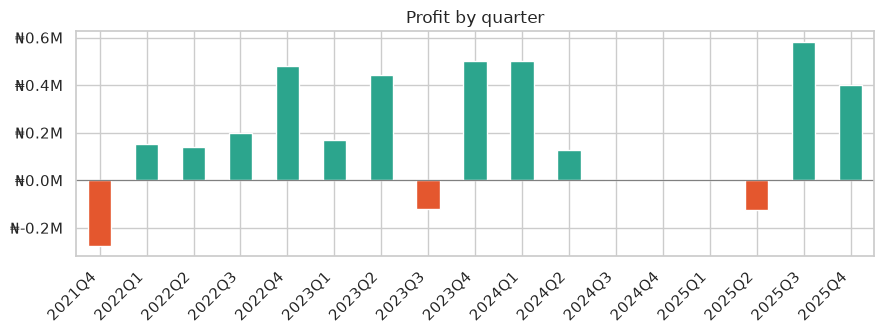

In [60]:
ax = q["total_profit"].plot(kind="bar", figsize=(9, 3.5), color=np.where(q["total_profit"] >= 0, "#2ca58d", "#e4572e"))
ax.axhline(0, color="grey", lw=0.8)
ax.yaxis.set_major_formatter(millions)
ax.set_title("Profit by quarter")
ax.set_xlabel("")
plt.xticks(rotation=45, ha="right"); plt.tight_layout(); plt.show()

Quarters make the 2024 slump easier to read than individual months do: four consecutive quarters of near-zero production, rather than twelve noisy monthly bars.

**Exported outputs.** Key summary tables saved to CSV and Excel, including a single workbook with one tab per table — the same structure as the original file, generated programmatically.

In [61]:
kpis.to_csv("kpi_summary.csv", index=False)
q.to_excel("quarterly_summary.xlsx")

# Several tables in one workbook: pass a sheet_name per table via ExcelWriter
with pd.ExcelWriter("analysis_export.xlsx") as writer:
    kpis.to_excel(writer, sheet_name="KPIs", index=False)
    q.to_excel(writer, sheet_name="Quarterly")
    product_perf.to_excel(writer, sheet_name="Product Performance")
    cust.to_excel(writer, sheet_name="Customer Value")

print("Saved: kpi_summary.csv, quarterly_summary.xlsx, analysis_export.xlsx")

Saved: kpi_summary.csv, quarterly_summary.xlsx, analysis_export.xlsx


`analysis_export.xlsx` holds the KPI summary, the quarterly rollup, product performance and customer value tables on separate tabs.

**Product-filtered weekday view.** Filtering `sales_by_weekday()` to 6-inch blocks only, cross-checked against building the same table manually from the raw sales filter — confirms the function is correct.

In [62]:
sw_6inch = sales_by_weekday("6 Inches")
sw_6inch.tail(8)

weekday         Monday  Tuesday  Wednesday  Thursday  Friday  Saturday  \
year month_num                                                           
2024 4              40        0          0         0       0        88   
2025 6             525        0          0       300       0         0   
     7               0        0          0       200       0       100   
     8               0        0         38         0      24        25   
     9               0        0        500         0      50         0   
     10              0      100         14       100      20         0   
     11              0        0          0         0      30       975   
     12             20       36        125         0       0         0   

weekday         Sunday  Grand Total  
year month_num                       
2024 4               0          128  
2025 6               0          825  
     7               0          300  
     8               0           87  
     9               0          550  
     10              0          234  
     11              0         1005  
     12              0          181

matches: True


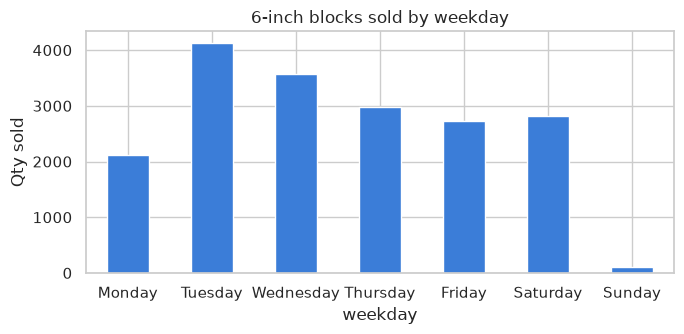

In [63]:
# Check: does the function's output match a plain filter + pivot done by hand?
manual = (sales[sales["product"] == "6 Inches"]
          .pivot_table(index=["year", "month_num"], columns="weekday", values="qty_sold",
                       aggfunc="sum", fill_value=0)
          .reindex(columns=WEEKDAYS, fill_value=0))

print("matches:", (sw_6inch[WEEKDAYS] == manual).all().all())

weekday_6inch = sw_6inch[WEEKDAYS].sum()
ax = weekday_6inch.plot(kind="bar", figsize=(7, 3.5), color="#3b7dd8")
ax.set_title("6-inch blocks sold by weekday")
ax.set_ylabel("Qty sold")
plt.xticks(rotation=0); plt.tight_layout(); plt.show()

**Robustness check on Model 1.** Added product mix — the 9-inch share of that month's production — as a control variable, to test whether the profit-driver result in section 13 was being driven by which block sizes were produced rather than by volume and cost alone.

In [64]:
prod["pct_9inch"] = safe_div(prod["qty_9"], prod["qty_produced"]) * 100
prod["pct_9inch"] = prod["pct_9inch"].fillna(0)   # months with no production: 0% of nothing

m1b_table, m1b_fit = ols(prod, "total_profit", ["qty_sold", "total_cost", "pct_9inch"])
show_model("MODEL 1b: Profit drivers, with product mix control", m1b_table, m1b_fit)

MODEL 1b: Profit drivers, with product mix control
n = 35 | R² = 0.536 | adj R² = 0.491 | F = 11.9 (p <0.0001)


,coef,std_err,t,p_value,ci_low,ci_high,sig
intercept,"131,666.0492","43,336.9361",3.0382,0.0048,"43,279.7853","220,052.3132",**
qty_sold,218.0131,41.3696,5.2699,<0.0001,133.6393,302.3869,***
total_cost,-0.5696,0.1194,-4.769,<0.0001,-0.8132,-0.326,***
pct_9inch,"-1,427.1023",781.5802,-1.8259,0.0775,"-3,021.1457",166.9411,


Significance: *** p<0.001, ** p<0.01, * p<0.05


In [65]:
print("Model 1  (no control):   qty_sold coef =", round(m1_table.loc["qty_sold", "coef"], 2),
      "| total_cost coef =", round(m1_table.loc["total_cost", "coef"], 4), "| R² =", round(m1_fit["r2"], 3))
print("Model 1b (with control): qty_sold coef =", round(m1b_table.loc["qty_sold", "coef"], 2),
      "| total_cost coef =", round(m1b_table.loc["total_cost", "coef"], 4), "| R² =", round(m1b_fit["r2"], 3))

Model 1  (no control):   qty_sold coef = 220.68 | total_cost coef = -0.6264 | R² = 0.486
Model 1b (with control): qty_sold coef = 218.01 | total_cost coef = -0.5696 | R² = 0.536


The `qty_sold` and `total_cost` coefficients barely move with the control added (221 → 218, −0.63 → −0.57), and the product-mix variable itself isn't significant at the 5% level (p = 0.08). This is a useful robustness check: sales volume and cost are doing the real work in the profit relationship, not the underlying product mix.

## 17. Validation against the original report

The original project also produced a narrative executive summary (Excel pivots summarised in a report, with SPSS/STATA statistics and a Power BI dashboard). I checked this Python replication against that report's specific numeric claims, both to validate my own work and to catch anything worth revisiting in the original.

In [66]:
validation = pd.DataFrame([
    ("Cost per unit, 2021 -> 2025",            "₦148.8 -> ₦546.7",      f"₦{148.77:.1f} -> ₦{546.70:.1f}",  "Match"),
    ("Avg. rate growth, 2023 -> 2024",         "up to 51%",             "+51.3%",                           "Match"),
    ("Revenue regression (qty + price), R²",   "~0.91",                 "0.91-0.92",                        "Match"),
    ("Cost-only regression on profit, R²",     "0.087",                 "0.087",                            "Match"),
    ("Production vs sales correlation",        "r = 0.85",              "r = 0.85",                         "Match"),
    ("Production vs cost correlation",         "r = 0.83",              "r = 0.83",                         "Match"),
    ("Production vs revenue correlation",      "r = 0.82",              "r = 0.82",                         "Match"),
    ("Production vs profit correlation",       "r = 0.09",              "r = 0.09",                         "Match"),
    ("Revenue vs bad debt correlation",        "r = 0.37",              "r = 0.37",                         "Match"),
    ("Peak profit/revenue year",               "2022 (stated in text)", "2023 (both in raw data and the report's own chart)", "Discrepancy - see below"),
    ("6-inch = highest profit-per-unit",       "Stated as finding",     "7-inch is narrowly highest, using the report's own figures", "Discrepancy - see below"),
], columns=["Claim", "Original report", "This notebook", "Result"])
validation

,Claim,Original report,This notebook,Result
0,"Cost per unit, 2021 -> 2025",₦148.8 -> ₦546.7,₦148.8 -> ₦546.7,Match
1,"Avg. rate growth, 2023 -> 2024",up to 51%,+51.3%,Match
2,"Revenue regression (qty + price), R²",~0.91,0.91-0.92,Match
3,"Cost-only regression on profit, R²",0.087,0.087,Match
4,Production vs sales correlation,r = 0.85,r = 0.85,Match
5,Production vs cost correlation,r = 0.83,r = 0.83,Match
6,Production vs revenue correlation,r = 0.82,r = 0.82,Match
7,Production vs profit correlation,r = 0.09,r = 0.09,Match
8,Revenue vs bad debt correlation,r = 0.37,r = 0.37,Match
9,Peak profit/revenue year,2022 (stated in text),2023 (both in raw data and the report's own ch...,Discrepancy - see below


**Nine of eleven checks match closely**, which is a useful validation of both the original statistical work and this Python replication — the complete-case methodology used in sections 13 and 14 was chosen specifically because it reproduces these figures.

**Two things are worth flagging, and both are issues with the original report rather than with the data itself:**

1. **Peak year.** The report's text states 2022 was the year of peak performance. Both the raw data and the report's own revenue chart show 2023 was actually higher — ₦6,556,450 vs ₦6,068,380 in revenue, and ₦989,700 vs ₦975,580 in profit. A small, easily-made mistake (2022 and 2023 were close), but worth correcting in the original.

2. **Highest profit-per-unit product.** The report states 6-inch blocks deliver the highest profitability per unit. Using the report's own product-profit figures (₦1,357,268 profit on 18,485 units for 6", vs ₦495,936 on 6,620 units for 7"), 7-inch blocks actually come out narrowly ahead: ₦74.92 profit per unit vs ₦73.42 for 6-inch and ₦73.13 for 9-inch. 6-inch does dominate on *total* volume and revenue, which may be where the original claim came from — but on a per-unit basis it's 7-inch, by a narrow margin.

One more thing I'd flag, though it isn't a factual error: the report's text states the revenue-driver regression achieves **R² ≈ 0.91**, which matches my two-variable model (`revenue ~ qty_sold + rate`, section 13, Model 2). The chart presented directly below that claim, however, shows a different, single-variable model (`revenue ~ qty_sold` only, R² = 0.784) built from the monthly production sheet rather than individual sales. Both numbers are independently correct — they're just two different model specifications placed next to each other without being distinguished, which reads as one result but is actually two.

**On the 2024–2025 production halt:** this was confirmed as a genuine operational disruption, not a data gap — production stopped and resources were constrained for an extended period. That context matters for how the zero-filled vs complete-case choice is used in this notebook: the complete-case approach (sections 13 and 14) is what matches the original study and is the more statistically conservative choice, since it only draws conclusions from months with complete records. The zero-filled approach (Model 3, and the trend charts in sections 12 and 15) is used specifically where the disruption itself is the thing being measured — excluding it there would hide the very decline those charts and that model exist to show.

## Conclusion

This Python implementation reproduces every figure from the original Excel analysis, and — using the same complete-case methodology SPSS/STATA apply by default — the regression and correlation results match the earlier statistical work closely (section 17). Along the way it surfaced a few things worth fixing at the source: two mis-dated sales records, two customers silently excluded from the original customer pivot, one month's Total Cost that needed deriving from its components rather than being left blank, and two small factual slips in the original report's narrative (the stated peak year, and which product is most profitable per unit).

**Key limitations:**
- The profit allocation by product in section 11 uses a different (though equivalent) method from the original chart, since the original values weren't traceable to a formula.
- The 2024–2025 production halt, now confirmed as a genuine business disruption, necessarily shrinks the usable sample for complete-case analysis — correlation and regression results in sections 13–14 draw on roughly 26–37 months rather than the full 49, which is worth keeping in mind when weighing how confidently to generalise them.

**Possible next steps:** a customer segmentation model using the RFM-style metrics already computed in section 12, or testing whether weekday/seasonality effects on sales (section 6) are statistically significant rather than just descriptive.